# Importação de Bibliotecas

In [1]:
import os #organizador de pasta
import numpy as np #estruturação dos dados
import matplotlib.pyplot as plt #plot gráfico
import seaborn as sns #plot gráfico
from PIL import Image #visualização de img
import pandas as pd #estruturação dos dados
from util import meus_uteis, timeProcess
import joblib #convertendo imagens em valores numéricos .gz
import scipy.stats as stats # Estatistical analises
import statsmodels.api as sm # Regression model

# CHO-745 - GST

In [2]:
os.listdir("data")

['imagem_conjunto',
 'imagens de contraste de fase (CHO745)',
 'imagens de fluorescencia',
 'realcadas_verde_HBMEC',
 'realcadas_verde_HUVEC']

In [3]:
link = "data/imagem_conjunto/CHO-745/GST/"

lista_arquivos_fluo = [link+i for i in os.listdir(link) if "ch01.tif" in i]
len(lista_arquivos_fluo)

21

Abrindo a primeira imagem de GTS CHO 745:

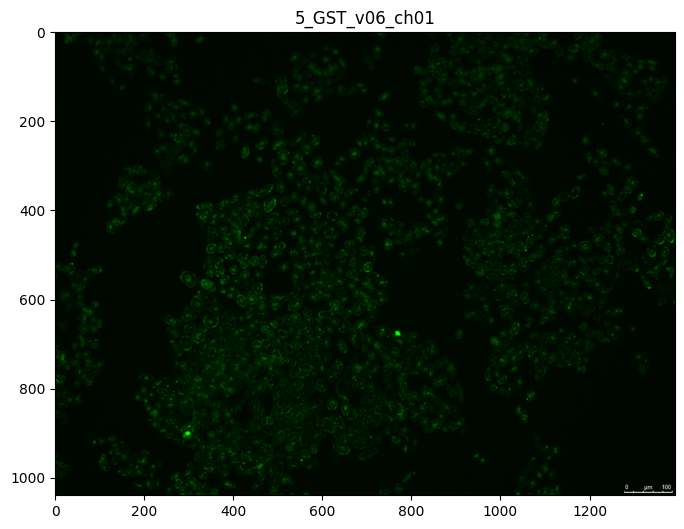

In [4]:
path = lista_arquivos_fluo[15] #chamando a primeira imagem
img = Image.open(path) #abrinado a primeira imagem

plt.figure(figsize=(8,8)) #tamanho da imagem
plt.imshow(img) #abrindo a imagem
plt.title(path[50:-4]) #título recortando o nome do título que corresponde o caminho da imagem[50:-4]
plt.show()

Convertendo a imagem escolhida para um DataFrame

In [5]:
#definindo uma função que converte as imagens em matriz numpy
def img_to_df(img) -> pd.DataFrame:
  img_array = np.array(img, dtype="float64")/255 #organizando o tamanho da matriz
  img_df = pd.DataFrame(columns=["red"], data=img_array[:,:,0].reshape(-1,1)) #aqui a cor vermelha da imagem foi anulada e os valores entraram como zero na coluna da df
  img_df["green"] = img_array[:,:,1].reshape(-1,1) # mantendo apenas a camada verde (de interesse)
  img_df["blue"] = img_array[:,:,2].reshape(-1,1) #mesma coisa que foi feita na camada vermelha foi feita com a azul

  return img_df

In [6]:
img_df_first = img_to_df(img=img) #chamando a função criada e como parâmetro está sendo passado a imagem organizada na pasta lá em cima.
img_df_first.head()

,red,green,blue
0,0.0,0.031373,0.0
1,0.0,0.027451,0.0
2,0.0,0.023529,0.0
3,0.0,0.031373,0.0
4,0.0,0.031373,0.0


Criando uma função para retirada do excesso de intensidade do pixel encontrados nas imagens:

Esse código foi criada para Calcular a frequencia em qu os pixels estão presentes na imagem. Quanto mais próximo o pixel esta de 1.0, vai verde é esse ponto e é o que precisa ser corrigido na imagem.

In [7]:
img_df_green = img_df_first['green'].copy() #copiando apenas a coluna verde da df original
freq = (
    img_df_green.value_counts(normalize=True)
    .to_frame()
    .reset_index()
    .rename(columns={'index':'green', 'green':'proportion'})
    .sort_values('green', ascending=False)
)
freq.head()

,green,proportion
65,1.000000,3.267297e-04
223,0.996078,6.907604e-07
209,0.992157,6.907604e-07
203,0.988235,6.907604e-07
226,0.980392,6.907604e-07


In [8]:
#somando os valores para ferificar se ele chegou ao valor 1.0
freq.sum()

green         108.058824
proportion      1.000000
dtype: float64

Retirando 5% da frequencia dos valores mais altos que representam a cor verde na imagem. O laço percorre do 1.0 até chegar no valor 0.05 (5%) e finaliza no valor de pixel que deve ser filtrado os valores acima ou igual a 0.05 para reduzir a intensidade de verde.

In [9]:
soma = 0 #igualando a variavel a 0
for n in range(len(freq)): #iteração para percorrer na df e somar os valores da coluna 1
  soma += freq.iloc[n,1]
  if soma >= 0.001: #0,1% dos dados
    print(soma)
    break
print(freq.iloc[n,:])

0.001013345490716181
green         0.427451
proportion    0.000023
Name: 110, dtype: float64


In [10]:
img_df_second = img_df_first.copy()
novo_valor = 0.0  # converter os valores em zero
display(freq.iloc[n,0])
img_df_second.loc[img_df_second['green'] >= freq.iloc[n,0], 'green'] = novo_valor
img_df_second.head()

0.42745098039215684

,red,green,blue
0,0.0,0.031373,0.0
1,0.0,0.027451,0.0
2,0.0,0.023529,0.0
3,0.0,0.031373,0.0
4,0.0,0.031373,0.0


#Plotando o boxplot com dados originais e retirada de outliers

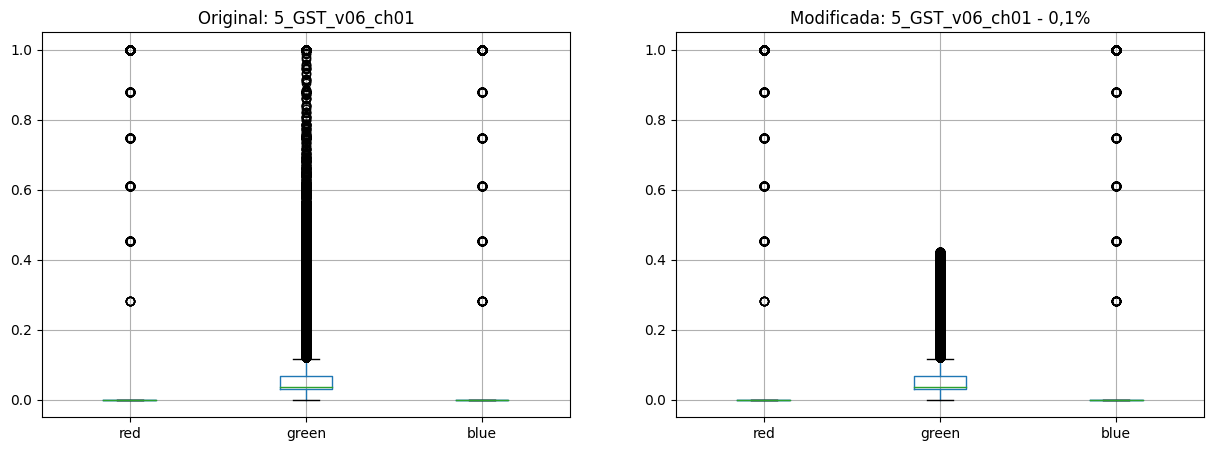

In [11]:
plt.figure(figsize=(15,5))

plt.subplot(1, 2, 1)
plt.title(f"Original: {path[50:-4]}")
img_df_first.boxplot()


plt.subplot(1, 2, 2)
plt.title(f"Modificada: {path[50:-4]} - 0,1%")
img_df_second.boxplot()

plt.show()

In [12]:
def bland_altman_grafic(valores_observados, valores_preditos, title) -> None:
# valores_observados = img_df_first['green']
# valores_preditos = img_df_second['green']

    # 1. Reporte da Regressão Linear (Slope e Intercept)
    slope, intercept, r_value, p_value, std_err = stats.linregress(
        valores_preditos, valores_observados
    )
    print(f'Regression Analysis:')
    print(f'Slope = {slope:.4f} (Ideally close to 1.0)')
    print(f'Intercept = {intercept:.4f} (Ideally close to 0.0)')
    print(f'Pearson R = {r_value:.4f}')

    # 2. Gráfico de Bland-Altman
    f, ax = plt.subplots(1, figsize=(8, 6))
    sm.graphics.mean_diff_plot(valores_observados, valores_preditos, ax=ax)

    plt.title(f'Bland-Altman Chart: {title}')
    plt.xlabel('Original and Corrected data Mean')
    plt.ylabel('Difference (Original - Corrected)')

    # 3. Inserindo as estatísticas dentro do gráfico
    stats_text = (
        f'Slope: {slope:.4f}\n'
        f'Intercept: {intercept:.4f}\n'
        f'Pearson R: {r_value:.4f}'
    )

    # Adicionando a caixa de texto no canto superior esquerdo (coordenadas relativas aos eixos)
    ax.text(
        0.05,
        0.95,
        stats_text,
        transform=ax.transAxes,  # Usa coordenadas relativas (0 a 1) do eixo
        fontsize=10,
        verticalalignment='top',
        bbox=dict(
            boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='gray'
        ),
    )

    # Salva o gráfico completo com a tabela embutida
    nome_arquivo = f'./data/imagem_conjunto/bland-altman_analysis_{title.lower().replace(" ", "_")}.png'
    plt.savefig(nome_arquivo, dpi=600)

    plt.show()

    return None


Regression Analysis:
Slope = 0.9779 (Ideally close to 1.0)
Intercept = 0.0019 (Ideally close to 0.0)
Pearson R = 0.8712


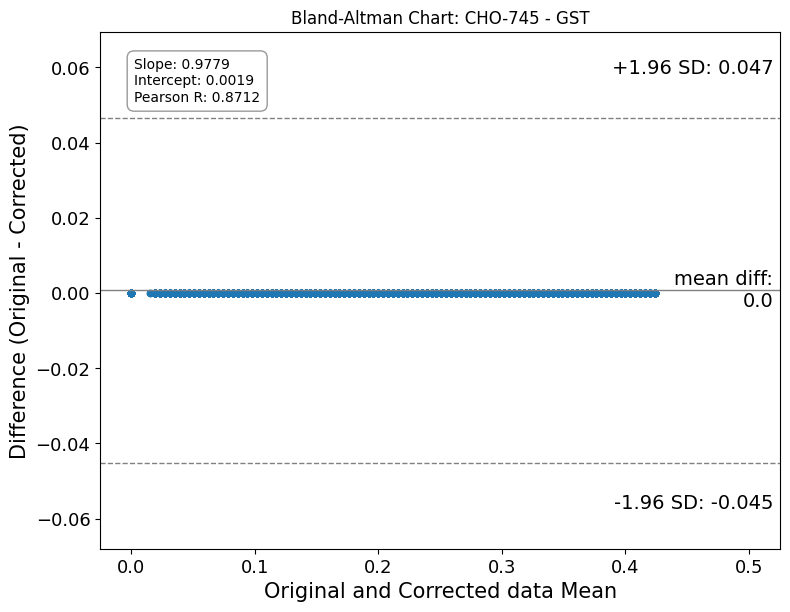

In [13]:
title = 'CHO-745 - GST'
bland_altman_grafic(valores_observados=img_df_first['green'], valores_preditos=img_df_second['green'], title=title)

In [14]:
# Sua função original (com ajuste robusto de compatibilidade para nomes de colunas no pandas)
def corrigir_pixel(img_df_first, threshold=0.001):
  img_df_green = img_df_first['green'].copy() #copiando apenas a coluna verde da df original
  freq = (
      img_df_green.value_counts(normalize=True)
      .to_frame()
      .reset_index()
      .rename(columns={'index':'green', 'green':'proportion'})
      .sort_values('green', ascending=False)
  )
  soma = 0 #igualando a variavel a 0
  for n in range(len(freq)): #iteração para percorrer na df e somar os valores da coluna 1
    soma += freq.iloc[n,1]
    if soma >= 0.001: #0,1% dos dados
      break
  img_df_second = img_df_first.copy()
  novo_valor = 0.0  # converter os valores em zero
  img_df_second.loc[img_df_second['green'] >= freq.iloc[n,0], 'green'] = novo_valor
  return img_df_second

In [15]:
# Comparando valores obtidos na função e manuamente
(corrigir_pixel(img_df_first) != img_df_second).sum()

red      0
green    0
blue     0
dtype: int64

In [16]:
def analise_indice_corte(df_test, title):
    thresholds = [0.0001, 0.0005, 0.001, 0.002, 0.005, 0.01]
    resultados = []

    for t in thresholds:
        # Aplica a correção com o threshold atual
        df_corrigido = corrigir_pixel(df_test, threshold=t)

        # Calcula a MFI (Média da intensidade de fluorescência na coluna verde)
        mfi_valor = df_corrigido['green'].mean()

        resultados.append({
            'Threshold (%)': f'{t * 100:.2f}%',
            'Resulting MFI': f'{mfi_valor:.4f}',
        })

    # Converte os resultados em DataFrame para visualização tabular
    df_sensibilidade = pd.DataFrame(resultados)

    # Imprime no console em inglês
    print(f'--- Sensitivity Analysis Table ({title}) ---')
    print(df_sensibilidade.to_string(index=False))
    print('\n' + '=' * 50 + '\n')

    # --- GERAÇÃO DO GRÁFICO COM TABELA EMBUTIDA ---
    fig, ax = plt.subplots(figsize=(9, 6))

    # Extrai valores numéricos para a plotagem
    x_vals = [t * 100 for t in thresholds]
    y_vals = [float(r['Resulting MFI']) for r in resultados]

    ax.plot(
        x_vals, y_vals, marker='o', linestyle='-', color='b', linewidth=2, zorder=3
    )

    # Destaca o ponto escolhido originalmente (0.1%)
    if 0.1 in x_vals:
        idx_orig = x_vals.index(0.1)
        val_orig = y_vals[idx_orig]
        ax.axvline(
            x=0.1,
            color='r',
            linestyle='--',
            label='Original Threshold (0.1%)',
            zorder=2,
        )
        ax.scatter(
            [0.1],
            [val_orig],
            color='r',
            zorder=5,
            label=f'Original MFI = {val_orig:.4f}',
        )

    ax.set_title(
        f'Impact of Artifact Threshold on MFI in {title}', fontsize=12, pad=15
    )
    ax.set_xlabel('Frequency Threshold (%)', fontsize=10)
    ax.set_ylabel('Average MFI (Green Channel)', fontsize=10)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='upper left')

    # --- INSERÇÃO DA TABELA DENTRO DO GRÁFICO ---
    table_data = [
        df_sensibilidade.columns.tolist()
    ] + df_sensibilidade.values.tolist()
    table = ax.table(
        cellText=table_data,
        loc='upper right',
        bbox=[0.62, 0.52, 0.35, 0.4],  # Posicionamento [left, bottom, width, height]
    )
    table.auto_set_font_size(False)
    table.set_fontsize(8.5)

    # Estilização básica da tabela inserida
    for (row, col), cell in table.get_celld().items():
        if row == 0:
            cell.set_text_props(weight='bold', color='white')
            cell.set_facecolor('#4C72B0')
        else:
            cell.set_facecolor('#F0F4F8' if row % 2 == 0 else 'white')

    plt.tight_layout()

    # Salva o gráfico completo com a tabela embutida
    nome_arquivo = f'./data/imagem_conjunto/sensitivity_analysis_{title.lower().replace(" ", "_")}.png'
    plt.savefig(nome_arquivo, dpi=600)
    plt.show()

    return None

In [99]:
import numpy as np
from statsmodels.stats.weightstats import ttost_ind

# Simulando dados brutos de dois grupos independentes
np.random.seed(42)
grupo_controle = np.random.normal(loc=100, scale=5, size=40)
grupo_tratado = np.random.normal(loc=101, scale=5, size=40)

limite = 3.0

# Executando o TOST
resultado = ttost_ind(
    x1=grupo_controle, 
    x2=grupo_tratado, 
    low=-limite, 
    upp=limite, 
    usevar='unequal'
)

# Acessando os valores com os índices corretos da tupla aninhada
print("--- TOST para Dados Brutos Independentes ---")
print(f"P-value geral do TOST: {resultado[0]:.5f}")
print(f"  - Teste inferior (limite -{limite}): t = {resultado[1][0]:.4f}, p = {resultado[1][1]:.5f}")
print(f"  - Teste superior (limite +{limite}): t = {resultado[2][0]:.4f}, p = {resultado[2][1]:.5f}")

--- TOST para Dados Brutos Independentes ---
P-value geral do TOST: 0.16472
  - Teste inferior (limite -3.0): t = 0.9814, p = 0.16472
  - Teste superior (limite +3.0): t = -4.6157, p = 0.00001


In [100]:
import numpy as np
from statsmodels.stats.weightstats import ttost_paired

# Simulando dados pareados
np.random.seed(123)
dados_brutos = np.random.normal(50, 3, 30)
dados_corrigidos = dados_brutos + np.random.normal(0.2, 0.8, 30)

limite_pareado = 1.5

# Executando o TOST pareado
resultado_p = ttost_paired(
    x1=dados_brutos, 
    x2=dados_corrigidos, 
    low=-limite_pareado, 
    upp=limite_pareado
)

print("\n--- TOST para Dados Corrigidos / Pareados ---")
print(f"P-value geral do TOST: {resultado_p[0]:.5f}")
print(f"  - Teste inferior (limite -{limite_pareado}): t = {resultado_p[1][0]:.4f}, p = {resultado_p[1][1]:.5f}")
print(f"  - Teste superior (limite +{limite_pareado}): t = {resultado_p[2][0]:.4f}, p = {resultado_p[2][1]:.5f}")


--- TOST para Dados Corrigidos / Pareados ---
P-value geral do TOST: 0.00000
  - Teste inferior (limite -1.5): t = 6.5919, p = 0.00000
  - Teste superior (limite +1.5): t = -10.0710, p = 0.00000


--- Sensitivity Analysis Table (CHO-745 - GST) ---
Threshold (%) Resulting MFI
        0.01%        0.0562
        0.05%        0.0562
        0.10%        0.0562
        0.20%        0.0562
        0.50%        0.0562
        1.00%        0.0562




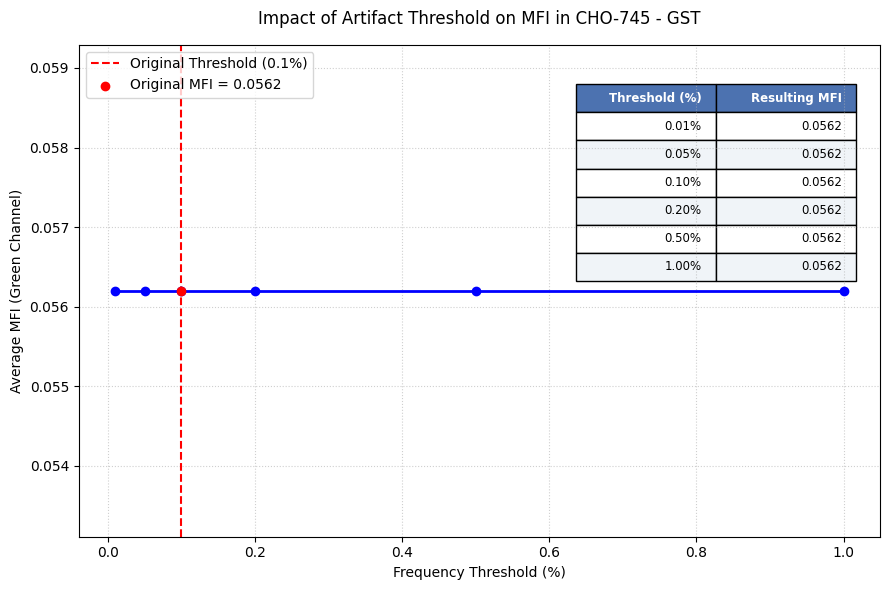

In [17]:
analise_indice_corte(df_test=img_df_first, title=title)

#Imagem original e pós nivelado os píxels:

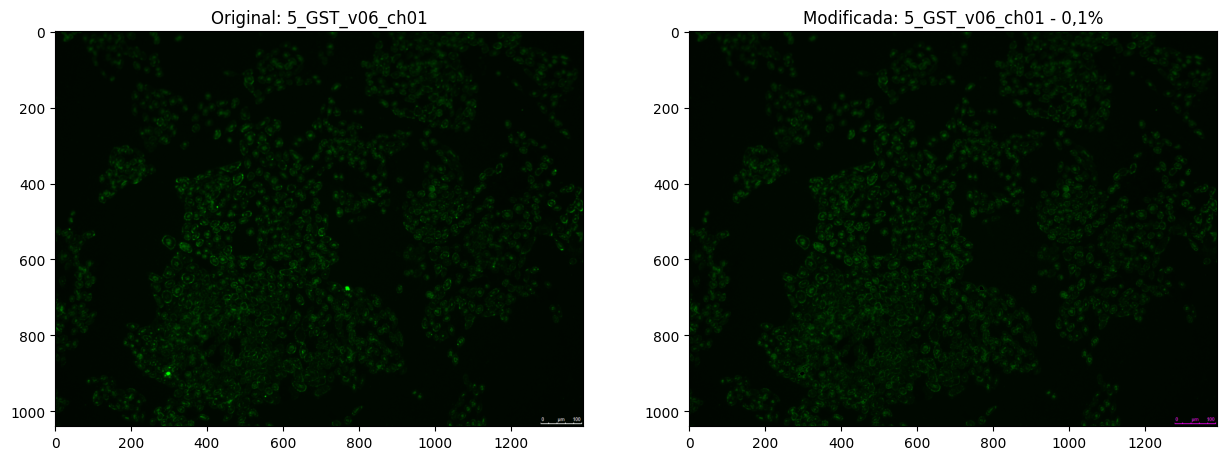

In [18]:

plt.figure(figsize=(15,15))

plt.subplot(1, 2, 1)
plt.imshow(np.array(img_df_first).reshape(1040, 1392, 3))
plt.title(f"Original: {path[50:-4]}")

plt.subplot(1, 2, 2)
plt.imshow(np.array(img_df_second).reshape(1040, 1392, 3))
plt.title(f"Modificada: {path[50:-4]} - 0,1%")

plt.show()

#Dataframe CHO 745 proteína GTS:

In [19]:
img_df_gst = pd.DataFrame() #criando uma df
img_dict = {} #criando um dicionário

for path in lista_arquivos_fluo:  #laço para pasta o que tiver em lista de arquivos controle
  path_key = path.split("Experiment_")[1][:-4]
  img = Image.open(path)              #abrinado a imagem que contem em path
  img_df_modif = img_df_second
  img_df_gst[path_key] = img_df_modif['green'] #renomeando a coluna com o final do nome do ar arquivo e sustituindo a coluna green

  img_dict[path_key] = img_df_modif

img_df_gst.head()

,CHO_745_GST_anti_v01_ch01,CHO_745_GST_anti_v02_ch01,CHO_745_GST_anti_v03_ch01,CHO_745_GST_anti_v04_ch01,CHO_745_GST_anti_v05_ch01,CHO_745_GST_anti_v06_ch01,CHO_745_GST_anti_v07_ch01,CHO_745_GST_anti_v08_ch01,CHO_745_GST_anti_v10_ch01,CHO_745_GST_anti_v9_ch01,...,CHO_745_GST_v02_ch01,CHO_745_GST_v03_ch01,CHO_745_GST_v04_ch01,CHO_745_GST_v05_ch01,CHO_745_GST_v06_ch01,CHO_745_GST_v07_ch01,CHO_745_GST_v08_ch01,CHO_745_GST_v09_ch01,CHO_745_GST_v10_ch01,CHO_745_GST_v11_ch01
0,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,...,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373
1,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,...,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451
2,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,...,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529
3,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,...,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373
4,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,...,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373


In [20]:
img_df_gst.describe()

,CHO_745_GST_anti_v01_ch01,CHO_745_GST_anti_v02_ch01,CHO_745_GST_anti_v03_ch01,CHO_745_GST_anti_v04_ch01,CHO_745_GST_anti_v05_ch01,CHO_745_GST_anti_v06_ch01,CHO_745_GST_anti_v07_ch01,CHO_745_GST_anti_v08_ch01,CHO_745_GST_anti_v10_ch01,CHO_745_GST_anti_v9_ch01,...,CHO_745_GST_v02_ch01,CHO_745_GST_v03_ch01,CHO_745_GST_v04_ch01,CHO_745_GST_v05_ch01,CHO_745_GST_v06_ch01,CHO_745_GST_v07_ch01,CHO_745_GST_v08_ch01,CHO_745_GST_v09_ch01,CHO_745_GST_v10_ch01,CHO_745_GST_v11_ch01
count,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,...,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06
mean,5.619096e-02,5.619096e-02,5.619096e-02,5.619096e-02,5.619096e-02,5.619096e-02,5.619096e-02,5.619096e-02,5.619096e-02,5.619096e-02,...,5.619096e-02,5.619096e-02,5.619096e-02,5.619096e-02,5.619096e-02,5.619096e-02,5.619096e-02,5.619096e-02,5.619096e-02,5.619096e-02
std,4.236068e-02,4.236068e-02,4.236068e-02,4.236068e-02,4.236068e-02,4.236068e-02,4.236068e-02,4.236068e-02,4.236068e-02,4.236068e-02,...,4.236068e-02,4.236068e-02,4.236068e-02,4.236068e-02,4.236068e-02,4.236068e-02,4.236068e-02,4.236068e-02,4.236068e-02,4.236068e-02
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,...,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02
50%,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,...,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02
75%,6.666667e-02,6.666667e-02,6.666667e-02,6.666667e-02,6.666667e-02,6.666667e-02,6.666667e-02,6.666667e-02,6.666667e-02,6.666667e-02,...,6.666667e-02,6.666667e-02,6.666667e-02,6.666667e-02,6.666667e-02,6.666667e-02,6.666667e-02,6.666667e-02,6.666667e-02,6.666667e-02
max,4.235294e-01,4.235294e-01,4.235294e-01,4.235294e-01,4.235294e-01,4.235294e-01,4.235294e-01,4.235294e-01,4.235294e-01,4.235294e-01,...,4.235294e-01,4.235294e-01,4.235294e-01,4.235294e-01,4.235294e-01,4.235294e-01,4.235294e-01,4.235294e-01,4.235294e-01,4.235294e-01


In [21]:
#salvando a df:
data = timeProcess()[1]
save = False
    
if save:
    joblib.dump(pd.DataFrame(img_df_gst), f'{link}save/dataframe-CHO745-GST-fluorescente-0,01%-{data}.gz')

#Chamando apenas as imagens dentro do VIR CHO-745:

# CHO-745 - VIR

In [22]:
link = "data/imagem_conjunto/CHO-745/VIR/"

lista_arquivos_fluo_vir = [link+i for i in os.listdir(link) if "ch01.tif" in i]
len(lista_arquivos_fluo_vir)

31

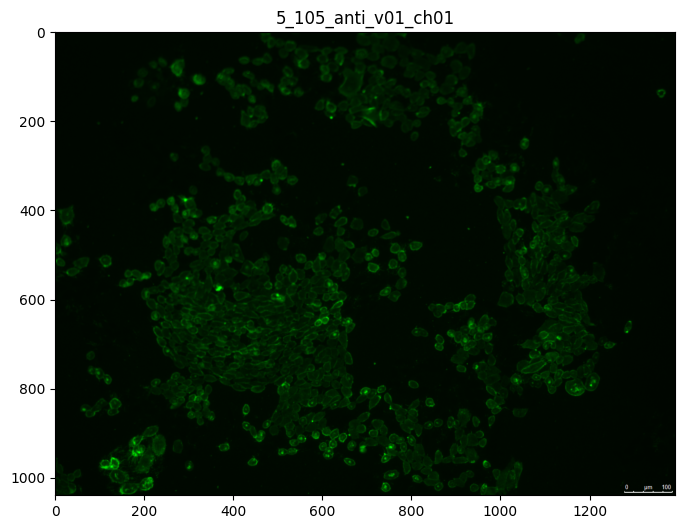

In [23]:
path = lista_arquivos_fluo_vir[10] #chamando a primeira imagem
img = Image.open(path) #abrinado a primeira imagem

plt.figure(figsize=(8,8)) #tamanho da imagem
plt.imshow(img) #abrindo a imagem
plt.title(path[50:-4]) #título recortando o nome do título que corresponde o caminho da imagem[50:-4]
plt.show()

In [24]:
img_df_vir = img_to_df(img=img) #chamando a função criada e como parâmetro está sendo passado a imagem organizada na pasta lá em cima.
img_df_vir.head()

,red,green,blue
0,0.0,0.031373,0.0
1,0.0,0.023529,0.0
2,0.0,0.031373,0.0
3,0.0,0.027451,0.0
4,0.0,0.027451,0.0


In [25]:
img_df_green = img_df_vir['green'].copy() #copiando apenas a coluna verde da df original
freq = (
    img_df_green.value_counts(normalize=True)
    .to_frame()
    .reset_index()
    .rename(columns={'index':'green', 'green':'proportion'})
    .sort_values('green', ascending=False)
)
freq.head()

,green,proportion
81,1.000000,2.728504e-04
246,0.992157,6.907604e-07
229,0.988235,2.072281e-06
243,0.984314,1.381521e-06
244,0.980392,1.381521e-06


In [26]:
soma = 0 #igualando a variavel a 0
for n in range(len(freq)): #iteração para percorrer na df e somar os valores da coluna 1
  soma += freq.iloc[n,1]
  if soma >= 0.001: #5% dos dados
    print(soma)
    break
print(freq.iloc[n,:])

0.001011963969938108
green         0.584314
proportion    0.000019
Name: 149, dtype: float64


In [27]:
img_df_vir_cho = img_df_vir.copy()

In [28]:
novo_valor = 0.0  # converter os valores em zero

display(freq.iloc[n,0])

img_df_vir_cho.loc[img_df_vir_cho['green'] >= freq.iloc[n,0], 'green'] = novo_valor
img_df_vir_cho.head()

0.5843137254901961

,red,green,blue
0,0.0,0.031373,0.0
1,0.0,0.023529,0.0
2,0.0,0.031373,0.0
3,0.0,0.027451,0.0
4,0.0,0.027451,0.0


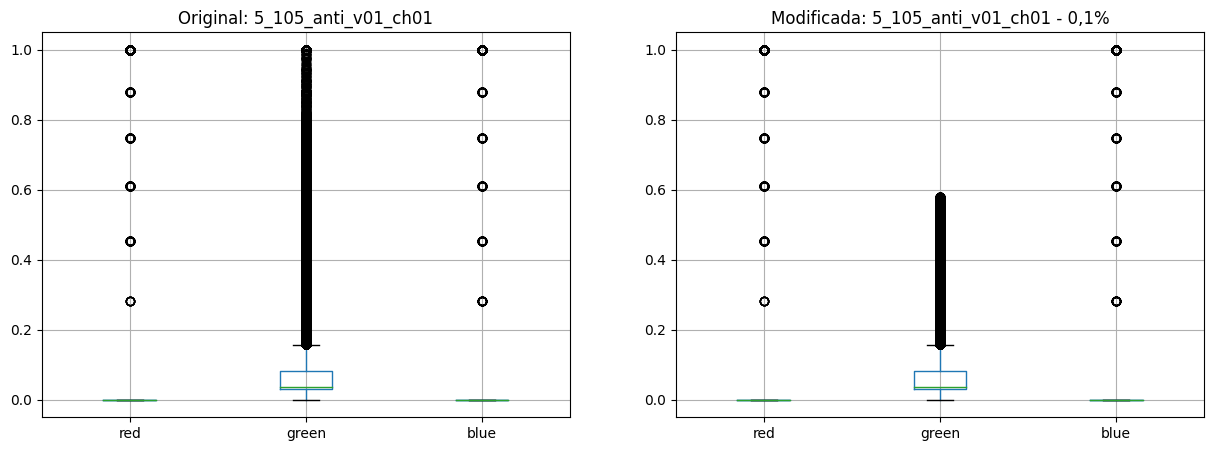

In [29]:
plt.figure(figsize=(15,5))

plt.subplot(1, 2, 1)
plt.title(f"Original: {path[50:-4]}")
img_df_vir.boxplot()

plt.subplot(1, 2, 2)
plt.title(f"Modificada: {path[50:-4]} - 0,1%")
img_df_vir_cho.boxplot()

plt.show()

Regression Analysis:
Slope = 0.9848 (Ideally close to 1.0)
Intercept = 0.0018 (Ideally close to 0.0)
Pearson R = 0.9133


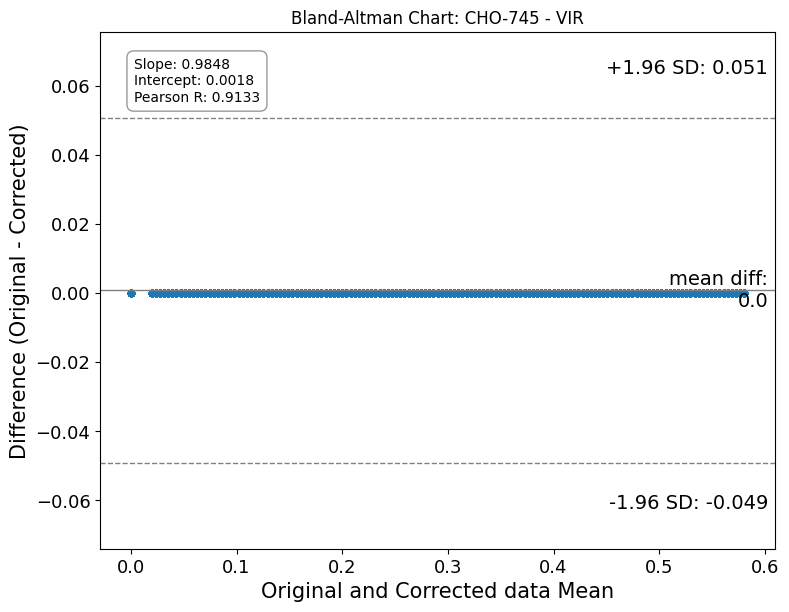

In [30]:
title='CHO-745 - VIR'
bland_altman_grafic(valores_observados=img_df_vir['green'], valores_preditos=img_df_vir_cho['green'], title=title)

--- Sensitivity Analysis Table (CHO-745 - VIR) ---
Threshold (%) Resulting MFI
        0.01%        0.0642
        0.05%        0.0642
        0.10%        0.0642
        0.20%        0.0642
        0.50%        0.0642
        1.00%        0.0642




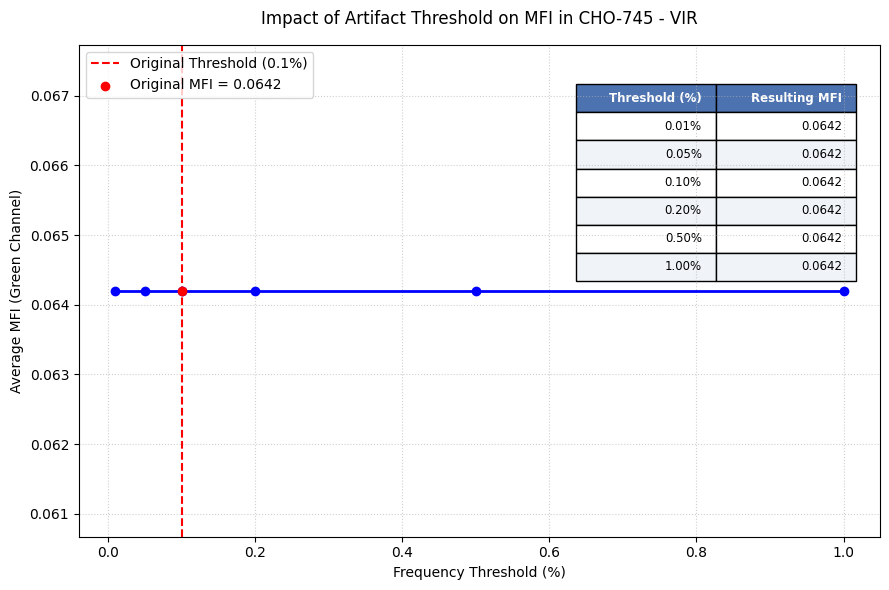

In [31]:
analise_indice_corte(df_test=img_df_vir, title=title)

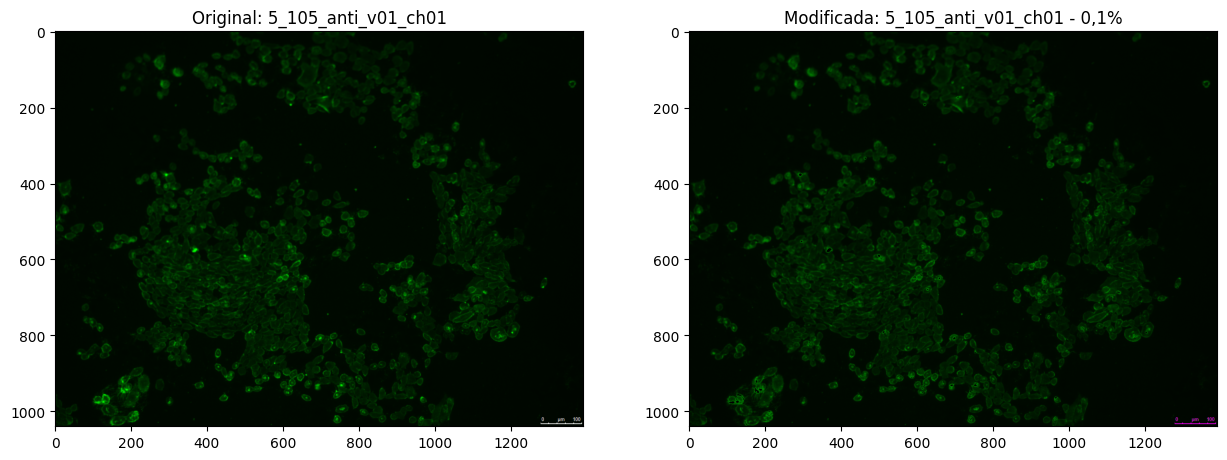

In [32]:
plt.figure(figsize=(15,15))

plt.subplot(1, 2, 1)
plt.imshow(np.array(img_df_vir).reshape(1040, 1392, 3))
plt.title(f"Original: {path[50:-4]}")

plt.subplot(1, 2, 2)
plt.imshow(np.array(img_df_vir_cho).reshape(1040, 1392, 3))
plt.title(f"Modificada: {path[50:-4]} - 0,1%")

plt.show()

In [33]:
img_df_grupo_vir= pd.DataFrame() #criando uma df
img_dict = {} #criando um dicionário

for path in lista_arquivos_fluo_vir:  #laço para pasta o que tiver em lista de arquivos controle
  path_key = path.split("Experiment_")[1][:-4]
  img = Image.open(path)              #abrinado a imagem que contem em path
  img_df_modif = img_df_vir_cho
  img_df_grupo_vir[path_key] = img_df_modif['green'] #renomeando a coluna com o final do nome do ar arquivo e sustituindo a coluna green

  img_dict[path_key] = img_df_modif

img_df_grupo_vir.head()

,CHO_745_096_anti_v01_ch01,CHO_745_096_anti_v02_ch01,CHO_745_096_anti_v03_ch01,CHO_745_096_anti_v04_ch01,CHO_745_096_anti_v05_ch01,CHO_745_096_v01_ch01,CHO_745_096_v02_ch01,CHO_745_096_v03_ch01,CHO_745_096_v04_ch01,CHO_745_096_v05_ch01,...,CHO_745_105_v02_ch01,CHO_745_105_v03_ch01,CHO_745_105_v04_ch01,CHO_745_105_v05_ch01,CHO_745_105_v06_ch01,CHO_745_105_v07_ch01,CHO_745_105_v08_ch01,CHO_745_105_v09_ch01,CHO_745_105_v10_ch01,CHO_745_105_v11_ch01
0,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,...,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373
1,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,...,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529
2,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,...,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373,0.031373
3,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,...,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451
4,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,...,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451,0.027451


In [34]:
img_df_grupo_vir.describe()

,CHO_745_096_anti_v01_ch01,CHO_745_096_anti_v02_ch01,CHO_745_096_anti_v03_ch01,CHO_745_096_anti_v04_ch01,CHO_745_096_anti_v05_ch01,CHO_745_096_v01_ch01,CHO_745_096_v02_ch01,CHO_745_096_v03_ch01,CHO_745_096_v04_ch01,CHO_745_096_v05_ch01,...,CHO_745_105_v02_ch01,CHO_745_105_v03_ch01,CHO_745_105_v04_ch01,CHO_745_105_v05_ch01,CHO_745_105_v06_ch01,CHO_745_105_v07_ch01,CHO_745_105_v08_ch01,CHO_745_105_v09_ch01,CHO_745_105_v10_ch01,CHO_745_105_v11_ch01
count,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,...,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06
mean,6.424265e-02,6.424265e-02,6.424265e-02,6.424265e-02,6.424265e-02,6.424265e-02,6.424265e-02,6.424265e-02,6.424265e-02,6.424265e-02,...,6.424265e-02,6.424265e-02,6.424265e-02,6.424265e-02,6.424265e-02,6.424265e-02,6.424265e-02,6.424265e-02,6.424265e-02,6.424265e-02
std,5.794698e-02,5.794698e-02,5.794698e-02,5.794698e-02,5.794698e-02,5.794698e-02,5.794698e-02,5.794698e-02,5.794698e-02,5.794698e-02,...,5.794698e-02,5.794698e-02,5.794698e-02,5.794698e-02,5.794698e-02,5.794698e-02,5.794698e-02,5.794698e-02,5.794698e-02,5.794698e-02
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,...,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02
50%,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,...,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02
75%,8.235294e-02,8.235294e-02,8.235294e-02,8.235294e-02,8.235294e-02,8.235294e-02,8.235294e-02,8.235294e-02,8.235294e-02,8.235294e-02,...,8.235294e-02,8.235294e-02,8.235294e-02,8.235294e-02,8.235294e-02,8.235294e-02,8.235294e-02,8.235294e-02,8.235294e-02,8.235294e-02
max,5.803922e-01,5.803922e-01,5.803922e-01,5.803922e-01,5.803922e-01,5.803922e-01,5.803922e-01,5.803922e-01,5.803922e-01,5.803922e-01,...,5.803922e-01,5.803922e-01,5.803922e-01,5.803922e-01,5.803922e-01,5.803922e-01,5.803922e-01,5.803922e-01,5.803922e-01,5.803922e-01


In [35]:
if save:
    joblib.dump(pd.DataFrame(img_df_grupo_vir), f'{link}save/dataframe-CHO745-VIR-fluorescente-0,01%-{data}.gz')

#Chamando apenas as imagens dentro do Controle CHO-745:

# CHO-745 - Ctrl

In [36]:
link = "data/imagem_conjunto/CHO-745/Controle/"

lista_arquivos_fluo_vir_ctrl = [link+i for i in os.listdir(link) if "ch01.tif" in i]
len(lista_arquivos_fluo_vir_ctrl)

26

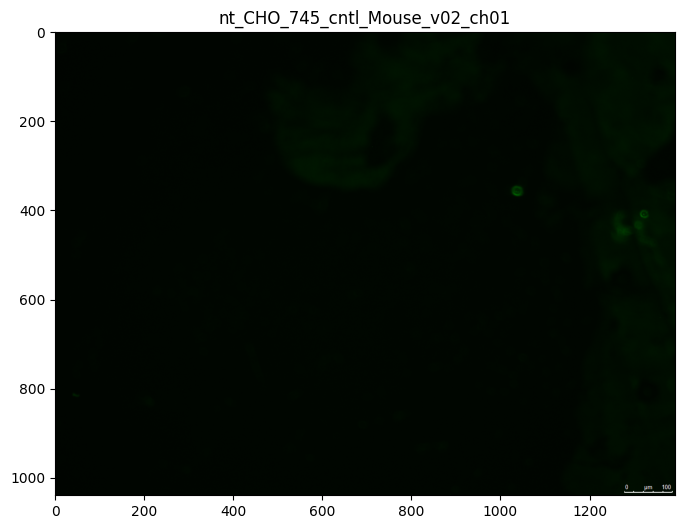

In [37]:
path = lista_arquivos_fluo_vir_ctrl[16] #chamando a primeira imagem
img = Image.open(path) #abrinado a primeira imagem

plt.figure(figsize=(8,8)) #tamanho da imagem
plt.imshow(img) #abrindo a imagem
plt.title(path[46:-4]) #título recortando o nome do título que corresponde o caminho da imagem[50:-4]
plt.show()

In [38]:
img_df = img_to_df(img=img) #chamando a função criada e como parâmetro está sendo passado a imagem organizada na pasta lá em cima.
img_df.head()

,red,green,blue
0,0.0,0.019608,0.0
1,0.0,0.019608,0.0
2,0.0,0.019608,0.0
3,0.0,0.019608,0.0
4,0.0,0.019608,0.0


In [39]:
img_df_green = img_df['green'].copy() #copiando apenas a coluna verde da df original
freq = (
    img_df_green.value_counts(normalize=True)
    .to_frame()
    .reset_index()
    .rename(columns={'index':'green', 'green':'proportion'})
    .sort_values('green', ascending=False)
)
freq.head()

,green,proportion
21,1.000000,0.000227
58,0.878431,0.000013
53,0.749020,0.000018
67,0.611765,0.000005
60,0.454902,0.000012


In [40]:
soma = 0 #igualando a variavel a 0
for n in range(len(freq)): #iteração para percorrer na df e somar os valores da coluna 1
  soma += freq.iloc[n,1]
  if soma >= 0.001: #5% dos dados
    print(soma)
    break
print(freq.iloc[n,:])

0.001012654730327144
green         0.164706
proportion    0.000063
Name: 37, dtype: float64


In [41]:
img_df_cntrl = img_df.copy()

In [42]:
novo_valor = 0.0  # converter os valores em zero

display(freq.iloc[n,0])
img_df_cntrl.loc[img_df_cntrl['green'] >= freq.iloc[n,0], 'green'] = novo_valor
img_df_cntrl.head()

0.16470588235294117

,red,green,blue
0,0.0,0.019608,0.0
1,0.0,0.019608,0.0
2,0.0,0.019608,0.0
3,0.0,0.019608,0.0
4,0.0,0.019608,0.0


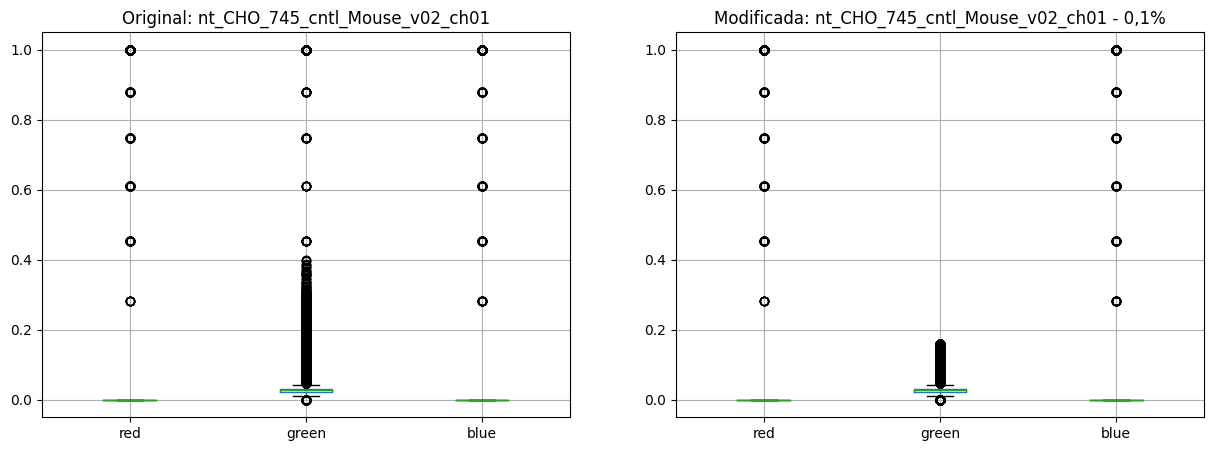

In [43]:
plt.figure(figsize=(15,5))

plt.subplot(1, 2, 1)
plt.title(f"Original: {path[46:-4]}")
img_df.boxplot()

plt.subplot(1, 2, 2)
plt.title(f"Modificada: {path[46:-4]} - 0,1%")
img_df_cntrl.boxplot()

plt.show()

Regression Analysis:
Slope = 0.9306 (Ideally close to 1.0)
Intercept = 0.0026 (Ideally close to 0.0)
Pearson R = 0.6039


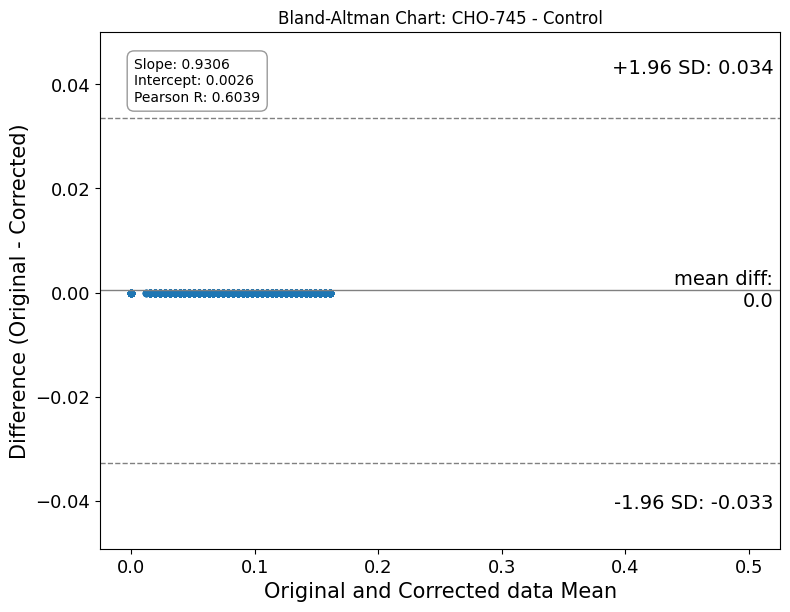

In [44]:
title='CHO-745 - Control'
bland_altman_grafic(valores_observados=img_df['green'], valores_preditos=img_df_cntrl['green'], title=title)

--- Sensitivity Analysis Table (CHO-745 - Control) ---
Threshold (%) Resulting MFI
        0.01%        0.0316
        0.05%        0.0316
        0.10%        0.0316
        0.20%        0.0316
        0.50%        0.0316
        1.00%        0.0316




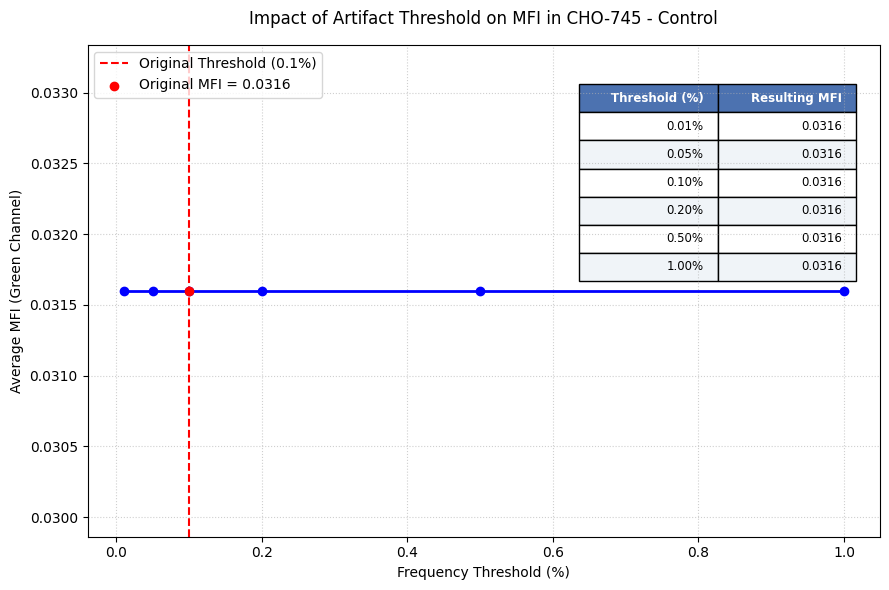

In [45]:
analise_indice_corte(df_test=img_df, title=title)

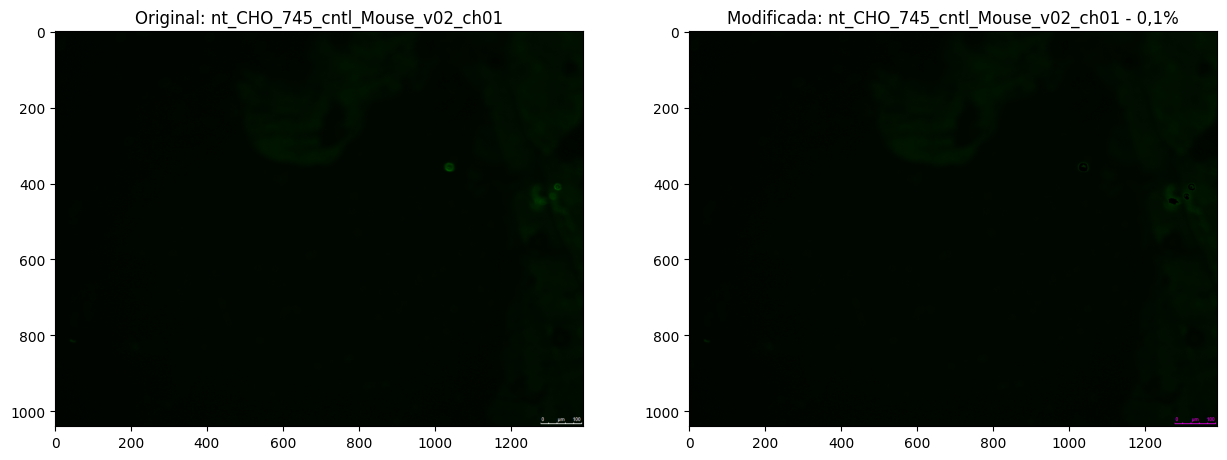

In [46]:
plt.figure(figsize=(15,15))

plt.subplot(1, 2, 1)
plt.imshow(np.array(img_df).reshape(1040, 1392, 3))
plt.title(f"Original: {path[46:-4]}")

plt.subplot(1, 2, 2)
plt.imshow(np.array(img_df_cntrl).reshape(1040, 1392, 3))
plt.title(f"Modificada: {path[46:-4]} - 0,1%")

plt.show()

In [47]:
img_df_grupo = pd.DataFrame() #criando uma df
img_dict = {} #criando um dicionário

for path in lista_arquivos_fluo_vir_ctrl:  #laço para pasta o que tiver em lista de arquivos controle
  path_key = path.split("Experiment_")[1][:-4]
  img = Image.open(path)              #abrinado a imagem que contem em path
  img_df_modif = img_df_cntrl
  img_df_grupo[path_key] = img_df_modif['green'] #renomeando a coluna com o final do nome do ar arquivo e sustituindo a coluna green

  img_dict[path_key] = img_df_modif

img_df_grupo.head()

,CHO_745_cntl_CHO_v01_ch01,CHO_745_cntl_CHO_v02_ch01,CHO_745_cntl_CHO_v03_ch01,CHO_745_cntl_CHO_v04_ch01,CHO_745_cntl_CHO_v05_ch01,CHO_745_cntl_ICAM_v01_ch01,CHO_745_cntl_ICAM_v02_ch01,CHO_745_cntl_ICAM_v03_ch01,CHO_745_cntl_ICAM_v04_ch01,CHO_745_cntl_ICAM_v05_ch01,...,CHO_745_cntl_Mouse_v02_ch01,CHO_745_cntl_Mouse_v03_ch01,CHO_745_cntl_Mouse_v04_ch01,CHO_745_cntl_Mouse_v05_ch01,CHO_745_cntl_Mouse_v06_ch01,CHO_745_cntl_Rabbit_v01_ch01,CHO_745_cntl_Rabbit_v02_ch01,CHO_745_cntl_Rabbit_v03_ch01,CHO_745_cntl_Rabbit_v04_ch01,CHO_745_cntl_Rabbit_v05_ch01
0,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,...,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608
1,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,...,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608
2,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,...,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608
3,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,...,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608
4,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,...,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608


In [48]:
img_df_grupo.describe()

,CHO_745_cntl_CHO_v01_ch01,CHO_745_cntl_CHO_v02_ch01,CHO_745_cntl_CHO_v03_ch01,CHO_745_cntl_CHO_v04_ch01,CHO_745_cntl_CHO_v05_ch01,CHO_745_cntl_ICAM_v01_ch01,CHO_745_cntl_ICAM_v02_ch01,CHO_745_cntl_ICAM_v03_ch01,CHO_745_cntl_ICAM_v04_ch01,CHO_745_cntl_ICAM_v05_ch01,...,CHO_745_cntl_Mouse_v02_ch01,CHO_745_cntl_Mouse_v03_ch01,CHO_745_cntl_Mouse_v04_ch01,CHO_745_cntl_Mouse_v05_ch01,CHO_745_cntl_Mouse_v06_ch01,CHO_745_cntl_Rabbit_v01_ch01,CHO_745_cntl_Rabbit_v02_ch01,CHO_745_cntl_Rabbit_v03_ch01,CHO_745_cntl_Rabbit_v04_ch01,CHO_745_cntl_Rabbit_v05_ch01
count,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,...,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06
mean,3.157799e-02,3.157799e-02,3.157799e-02,3.157799e-02,3.157799e-02,3.157799e-02,3.157799e-02,3.157799e-02,3.157799e-02,3.157799e-02,...,3.157799e-02,3.157799e-02,3.157799e-02,3.157799e-02,3.157799e-02,3.157799e-02,3.157799e-02,3.157799e-02,3.157799e-02,3.157799e-02
std,1.372855e-02,1.372855e-02,1.372855e-02,1.372855e-02,1.372855e-02,1.372855e-02,1.372855e-02,1.372855e-02,1.372855e-02,1.372855e-02,...,1.372855e-02,1.372855e-02,1.372855e-02,1.372855e-02,1.372855e-02,1.372855e-02,1.372855e-02,1.372855e-02,1.372855e-02,1.372855e-02
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02,...,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02
50%,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,...,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02
75%,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,...,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02,3.137255e-02
max,1.607843e-01,1.607843e-01,1.607843e-01,1.607843e-01,1.607843e-01,1.607843e-01,1.607843e-01,1.607843e-01,1.607843e-01,1.607843e-01,...,1.607843e-01,1.607843e-01,1.607843e-01,1.607843e-01,1.607843e-01,1.607843e-01,1.607843e-01,1.607843e-01,1.607843e-01,1.607843e-01


In [49]:
if save:
    joblib.dump(pd.DataFrame(img_df_grupo_vir), f'{link}save/dataframe-CHO745-Ctrl-fluorescente-0,01%-{data}.gz')

#Chamando apenas as imagens dentro do GST ICAM:

# CHO-ICAM - GST

In [50]:
link = "data/imagem_conjunto/CHO-ICAM/GST/"

lista_arquivos_gst_icam_fluo = [link+i for i in os.listdir(link) if "ch01.tif" in i]
len(lista_arquivos_gst_icam_fluo)

40

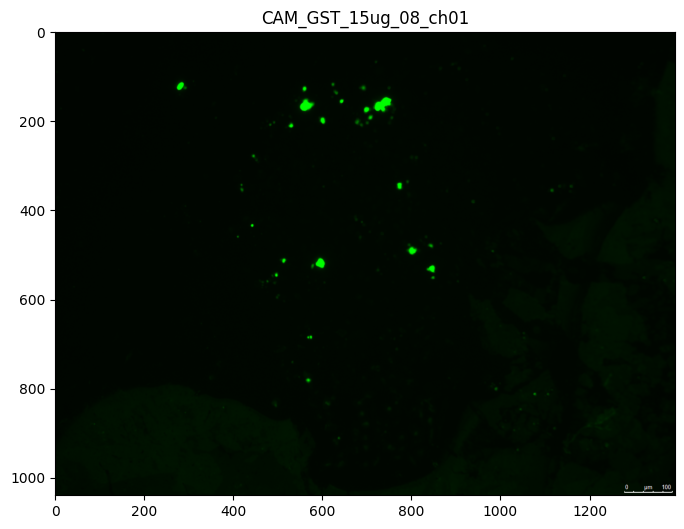

In [51]:
path = lista_arquivos_gst_icam_fluo[12] #chamando a primeira imagem
img = Image.open(path) #abrinado a primeira imagem

plt.figure(figsize=(8,8)) #tamanho da imagem
plt.imshow(img) #abrindo a imagem
plt.title(path[50:-4]) #título recortando o nome do título que corresponde o caminho da imagem[50:-4]
plt.show()

In [52]:
img_df = img_to_df(img=img) #chamando a função criada e como parâmetro está sendo passado a imagem organizada na pasta lá em cima.
img_df.head()

,red,green,blue
0,0.0,0.019608,0.0
1,0.0,0.019608,0.0
2,0.0,0.019608,0.0
3,0.0,0.019608,0.0
4,0.0,0.019608,0.0


In [53]:
img_df_green = img_df['green'].copy() #copiando apenas a coluna verde da df original
freq = (
    img_df_green.value_counts(normalize=True)
    .to_frame()
    .reset_index()
    .rename(columns={'index':'green', 'green':'proportion'})
    .sort_values('green', ascending=False)
)
freq.head()

,green,proportion
17,1.000000,0.001188
52,0.996078,0.000039
49,0.992157,0.000042
57,0.988235,0.000037
54,0.984314,0.000038


In [54]:
soma = 0 #igualando a variavel a 0
for n in range(len(freq)): #iteração para percorrer na df e somar os valores da coluna 1
  soma += freq.iloc[n,1]
  if soma >= 0.001: #5% dos dados
    print(soma)
    break
print(freq.iloc[n,:])

0.001188107869142352
green         1.000000
proportion    0.001188
Name: 17, dtype: float64


In [55]:
img_df_gst_icam = img_df.copy()

In [56]:
novo_valor = 0.0  # converter os valores em zero
display(freq.iloc[n,0])
img_df_gst_icam.loc[img_df_gst_icam['green'] >= freq.iloc[n,0], 'green'] = novo_valor
img_df_gst_icam.head()

1.0

,red,green,blue
0,0.0,0.019608,0.0
1,0.0,0.019608,0.0
2,0.0,0.019608,0.0
3,0.0,0.019608,0.0
4,0.0,0.019608,0.0


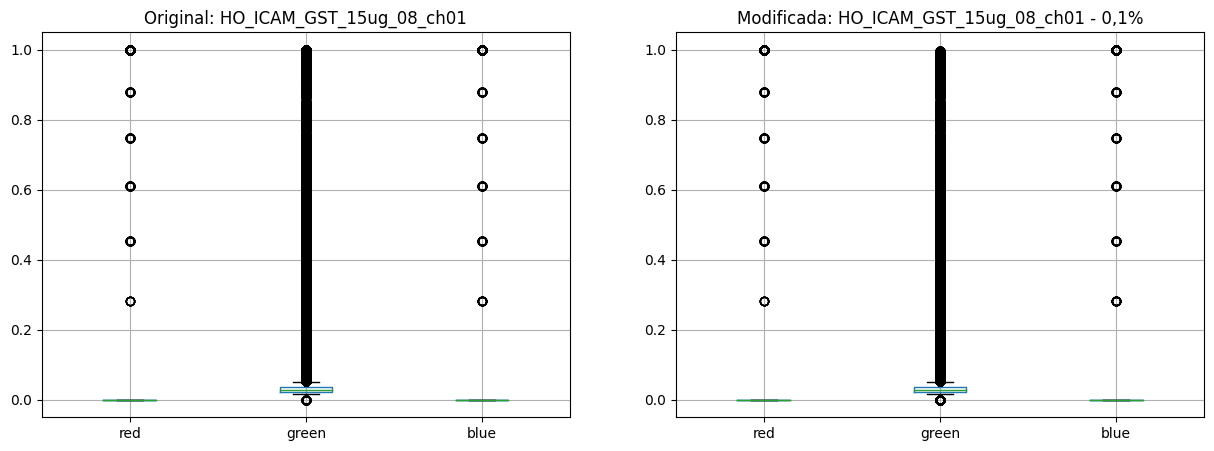

In [57]:
plt.figure(figsize=(15,5))

plt.subplot(1, 2, 1)
plt.title(f"Original: {path[46:-4]}")
img_df.boxplot()

plt.subplot(1, 2, 2)
plt.title(f"Modificada: {path[46:-4]} - 0,1%")
img_df_gst_icam.boxplot()

plt.show()

Regression Analysis:
Slope = 0.9575 (Ideally close to 1.0)
Intercept = 0.0027 (Ideally close to 0.0)
Pearson R = 0.6587


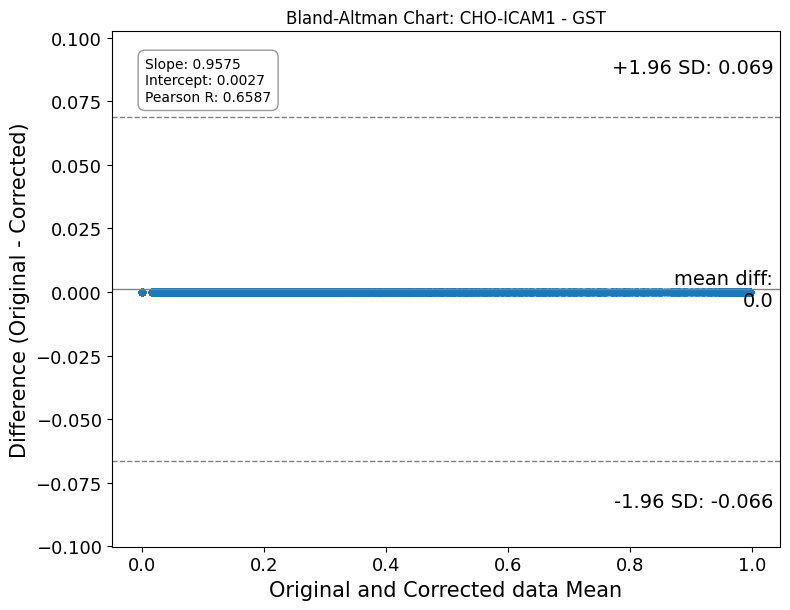

In [58]:
title='CHO-ICAM1 - GST'
bland_altman_grafic(valores_observados=img_df['green'], valores_preditos=img_df_gst_icam['green'], title=title)

--- Sensitivity Analysis Table (CHO-ICAM1 - GST) ---
Threshold (%) Resulting MFI
        0.01%        0.0355
        0.05%        0.0355
        0.10%        0.0355
        0.20%        0.0355
        0.50%        0.0355
        1.00%        0.0355




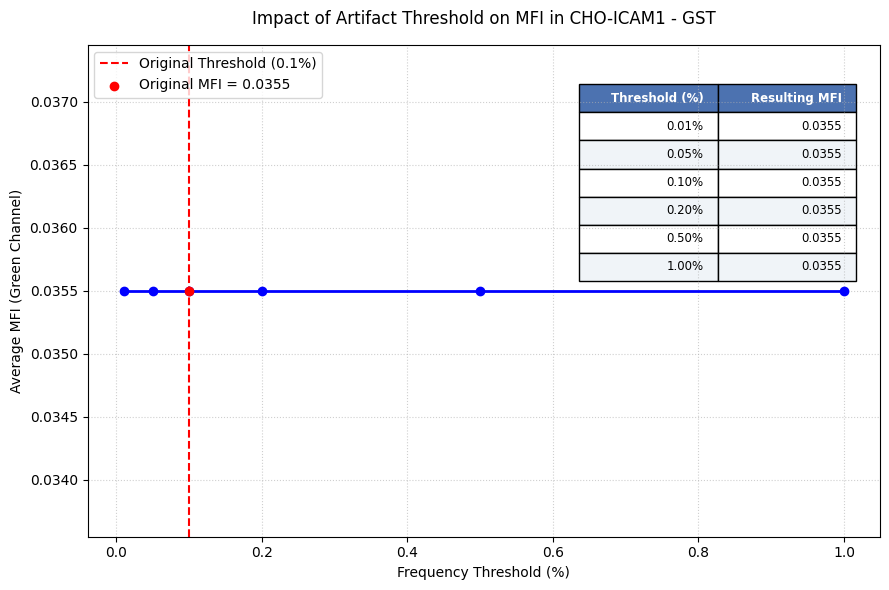

In [59]:
analise_indice_corte(df_test=img_df, title=title)

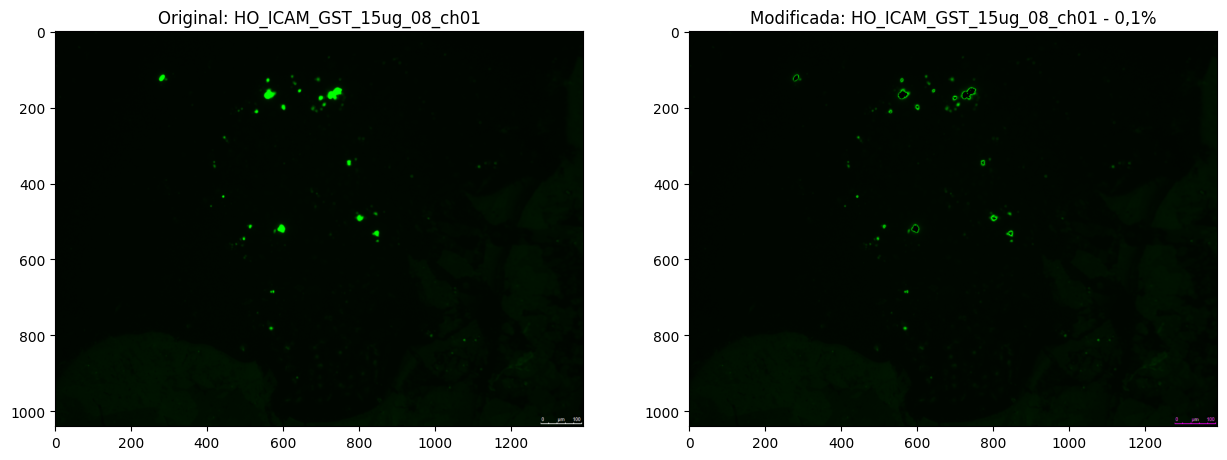

In [60]:
plt.figure(figsize=(15,15))

plt.subplot(1, 2, 1)
plt.imshow(np.array(img_df).reshape(1040, 1392, 3))
plt.title(f"Original: {path[46:-4]}")

plt.subplot(1, 2, 2)
plt.imshow(np.array(img_df_gst_icam).reshape(1040, 1392, 3))
plt.title(f"Modificada: {path[46:-4]} - 0,1%")

plt.show()

In [61]:
img_df_grupo = pd.DataFrame() #criando uma df
img_dict = {} #criando um dicionário

for path in lista_arquivos_gst_icam_fluo:  #laço para pasta o que tiver em lista de arquivos controle
  path_key = path.split("Experiment_")[1][:-4]
  img = Image.open(path)              #abrinado a imagem que contem em path
  img_df_modif = img_df_gst_icam
  img_df_grupo[path_key] = img_df_modif['green'] #renomeando a coluna com o final do nome do ar arquivo e sustituindo a coluna green

  img_dict[path_key] = img_df_modif

img_df_grupo.head()

,CHO_ICAM_GST_10ug_11_ch01,CHO_ICAM_GST_10ug_12_ch01,CHO_ICAM_GST_10ug_13_ch01,CHO_ICAM_GST_10ug_14_ch01,CHO_ICAM_GST_10ug_15_ch01,CHO_ICAM_GST_10ug_16_ch01,CHO_ICAM_GST_10ug_17_ch01,CHO_ICAM_GST_10ug_18_ch01,CHO_ICAM_GST_10ug_19_ch01,CHO_ICAM_GST_10ug_20_ch01,...,CHO_ICAM_GST_5ug_11_ch01,CHO_ICAM_GST_5ug_12_ch01,CHO_ICAM_GST_5ug_13_ch01,CHO_ICAM_GST_5ug_14_ch01,CHO_ICAM_GST_5ug_15_ch01,CHO_ICAM_GST_5ug_16_ch01,CHO_ICAM_GST_5ug_17_ch01,CHO_ICAM_GST_5ug_18_ch01,CHO_ICAM_GST_5ug_19_ch01,CHO_ICAM_GST_5ug_20_ch01
0,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,...,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608
1,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,...,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608
2,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,...,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608
3,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,...,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608
4,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,...,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608


In [62]:
img_df_grupo.describe()

,CHO_ICAM_GST_10ug_11_ch01,CHO_ICAM_GST_10ug_12_ch01,CHO_ICAM_GST_10ug_13_ch01,CHO_ICAM_GST_10ug_14_ch01,CHO_ICAM_GST_10ug_15_ch01,CHO_ICAM_GST_10ug_16_ch01,CHO_ICAM_GST_10ug_17_ch01,CHO_ICAM_GST_10ug_18_ch01,CHO_ICAM_GST_10ug_19_ch01,CHO_ICAM_GST_10ug_20_ch01,...,CHO_ICAM_GST_5ug_11_ch01,CHO_ICAM_GST_5ug_12_ch01,CHO_ICAM_GST_5ug_13_ch01,CHO_ICAM_GST_5ug_14_ch01,CHO_ICAM_GST_5ug_15_ch01,CHO_ICAM_GST_5ug_16_ch01,CHO_ICAM_GST_5ug_17_ch01,CHO_ICAM_GST_5ug_18_ch01,CHO_ICAM_GST_5ug_19_ch01,CHO_ICAM_GST_5ug_20_ch01
count,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,...,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06
mean,3.545173e-02,3.545173e-02,3.545173e-02,3.545173e-02,3.545173e-02,3.545173e-02,3.545173e-02,3.545173e-02,3.545173e-02,3.545173e-02,...,3.545173e-02,3.545173e-02,3.545173e-02,3.545173e-02,3.545173e-02,3.545173e-02,3.545173e-02,3.545173e-02,3.545173e-02,3.545173e-02
std,3.147088e-02,3.147088e-02,3.147088e-02,3.147088e-02,3.147088e-02,3.147088e-02,3.147088e-02,3.147088e-02,3.147088e-02,3.147088e-02,...,3.147088e-02,3.147088e-02,3.147088e-02,3.147088e-02,3.147088e-02,3.147088e-02,3.147088e-02,3.147088e-02,3.147088e-02,3.147088e-02
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02,...,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02,2.352941e-02
50%,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,...,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02
75%,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,...,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02,3.529412e-02
max,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01,...,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01


In [63]:
if save:
    joblib.dump(pd.DataFrame(img_df_grupo_vir), f'{link}save/dataframe-CHOICAM-GST-fluorescente-0,01%-{data}.gz')

#Chamando apenas as imagens dentro do VIR ICAM:

# CHO-ICAM - VIR

In [64]:
link = "data/imagem_conjunto/CHO-ICAM/VIR/"

lista_arquivos_vir_icam_fluo = [link+i for i in os.listdir(link) if "ch01.tif" in i]
len(lista_arquivos_vir_icam_fluo)

43

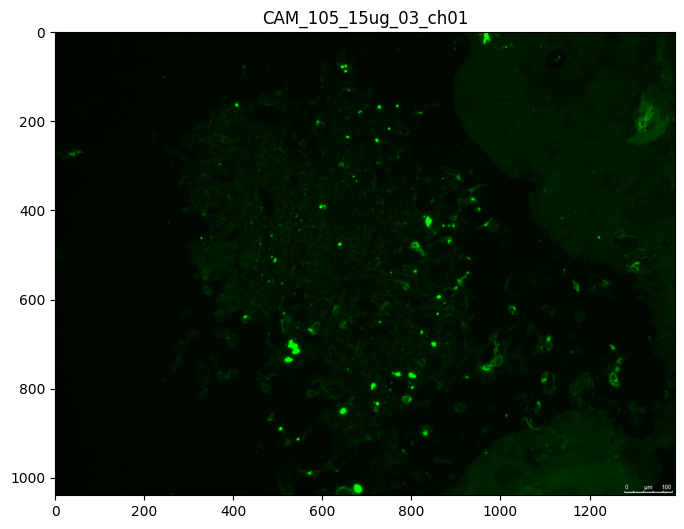

In [65]:
path = lista_arquivos_vir_icam_fluo[12] #chamando a primeira imagem
img = Image.open(path) #abrinado a primeira imagem

plt.figure(figsize=(8,8)) #tamanho da imagem
plt.imshow(img) #abrindo a imagem
plt.title(path[50:-4]) #título recortando o nome do título que corresponde o caminho da imagem[50:-4]
plt.show()

In [66]:
img_df = img_to_df(img=img) #chamando a função criada e como parâmetro está sendo passado a imagem organizada na pasta lá em cima.
img_df.head()

,red,green,blue
0,0.0,0.019608,0.0
1,0.0,0.019608,0.0
2,0.0,0.019608,0.0
3,0.0,0.023529,0.0
4,0.0,0.023529,0.0


In [67]:
img_df_green = img_df['green'].copy() #copiando apenas a coluna verde da df original
freq = (
    img_df_green.value_counts(normalize=True)
    .to_frame()
    .reset_index()
    .rename(columns={'index':'green', 'green':'proportion'})
    .sort_values('green', ascending=False)
)
freq.head()

,green,proportion
39,1.000000,0.001166
131,0.996078,0.000032
111,0.992157,0.000046
124,0.988235,0.000037
134,0.984314,0.000030


In [68]:
soma = 0 #igualando a variavel a 0
for n in range(len(freq)): #iteração para percorrer na df e somar os valores da coluna 1
  soma += freq.iloc[n,1]
  if soma >= 0.001: #5% dos dados
    print(soma)
    break
print(freq.iloc[n,:])

0.001166003536693192
green         1.000000
proportion    0.001166
Name: 39, dtype: float64


In [69]:
img_df_vir_icam = img_df.copy()

In [70]:
novo_valor = 0.0  # converter os valores em zero

display(freq.iloc[n,0])

img_df_vir_icam.loc[img_df_vir_icam['green'] >= freq.iloc[n,0], 'green'] = novo_valor
img_df_vir_icam.head()

1.0

,red,green,blue
0,0.0,0.019608,0.0
1,0.0,0.019608,0.0
2,0.0,0.019608,0.0
3,0.0,0.023529,0.0
4,0.0,0.023529,0.0


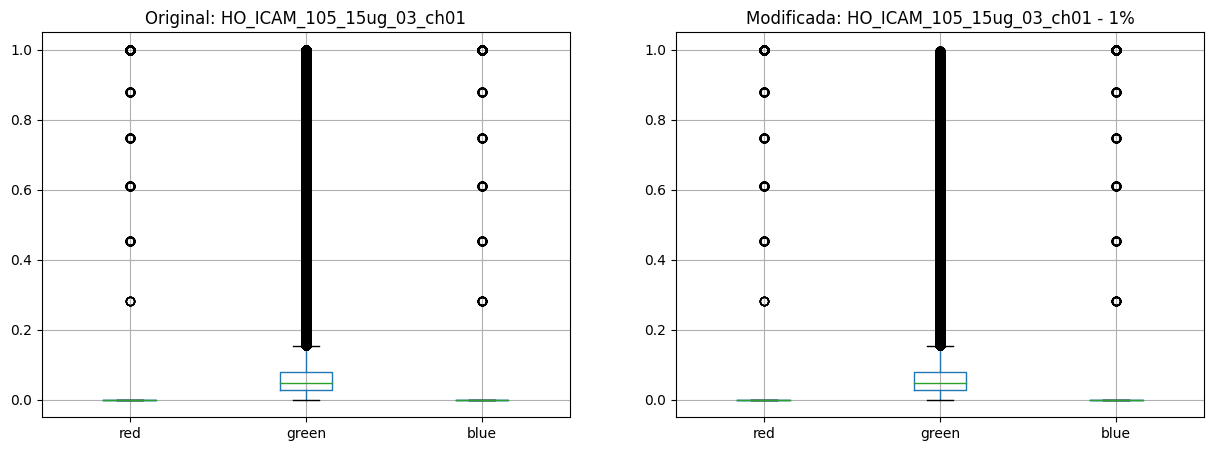

In [71]:
plt.figure(figsize=(15,5))

plt.subplot(1, 2, 1)
plt.title(f"Original: {path[46:-4]}")
img_df.boxplot()

plt.subplot(1, 2, 2)
plt.title(f"Modificada: {path[46:-4]} - 1%")
img_df_vir_icam.boxplot()

plt.show()

Regression Analysis:
Slope = 0.9722 (Ideally close to 1.0)
Intercept = 0.0028 (Ideally close to 0.0)
Pearson R = 0.8202


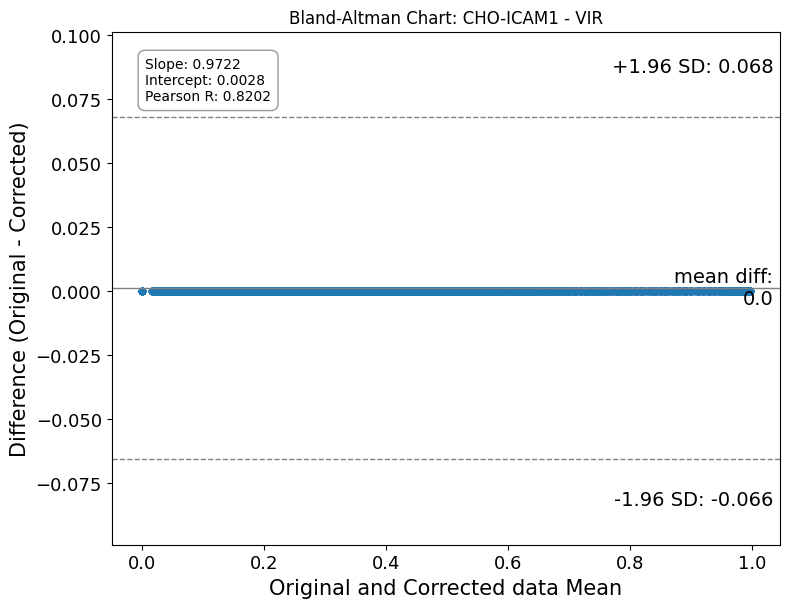

In [72]:
title='CHO-ICAM1 - VIR'
bland_altman_grafic(valores_observados=img_df['green'], valores_preditos=img_df_vir_icam['green'], title=title)

--- Sensitivity Analysis Table (CHO-ICAM1 - VIR) ---
Threshold (%) Resulting MFI
        0.01%        0.0602
        0.05%        0.0602
        0.10%        0.0602
        0.20%        0.0602
        0.50%        0.0602
        1.00%        0.0602




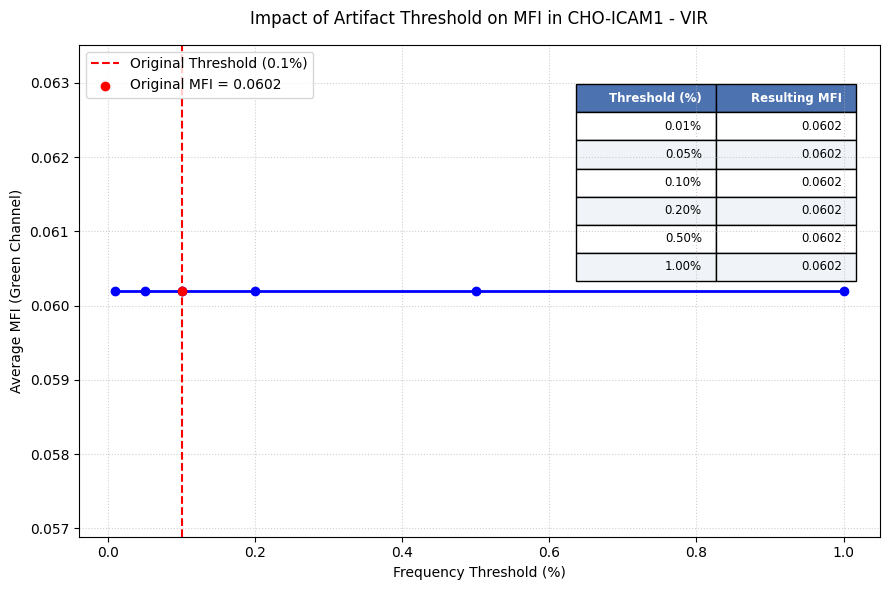

In [73]:
analise_indice_corte(df_test=img_df, title=title)

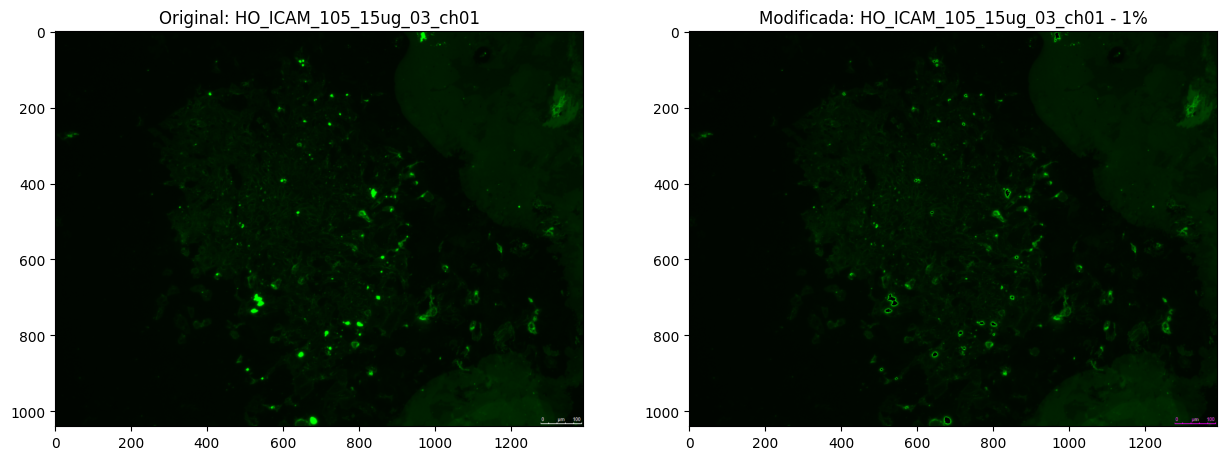

In [74]:
plt.figure(figsize=(15,15))

plt.subplot(1, 2, 1)
plt.imshow(np.array(img_df).reshape(1040, 1392, 3))
plt.title(f"Original: {path[46:-4]}")

plt.subplot(1, 2, 2)
plt.imshow(np.array(img_df_vir_icam).reshape(1040, 1392, 3))
plt.title(f"Modificada: {path[46:-4]} - 1%")

plt.show()

In [75]:
img_df_grupo = pd.DataFrame() #criando uma df
img_dict = {} #criando um dicionário

for path in lista_arquivos_vir_icam_fluo:  #laço para pasta o que tiver em lista de arquivos controle
  path_key = path.split("Experiment_")[1][:-4]
  img = Image.open(path)              #abrinado a imagem que contem em path
  img_df_modif = img_df_vir_icam
  img_df_grupo[path_key] = img_df_modif['green'] #renomeando a coluna com o final do nome do ar arquivo e sustituindo a coluna green

  img_dict[path_key] = img_df_modif

img_df_grupo.head()

,CHO_ICAM_105_10ug_01_ch01,CHO_ICAM_105_10ug_02_ch01,CHO_ICAM_105_10ug_03_ch01,CHO_ICAM_105_10ug_04_ch01,CHO_ICAM_105_10ug_05_ch01,CHO_ICAM_105_10ug_06_ch01,CHO_ICAM_105_10ug_07_ch01,CHO_ICAM_105_10ug_08_ch01,CHO_ICAM_105_10ug_09_ch01,CHO_ICAM_105_10ug_10_ch01,...,CHO_ICAM_105_5ug_03_ch01,CHO_ICAM_105_5ug_04_ch01,CHO_ICAM_105_5ug_05_ch01,CHO_ICAM_105_5ug_06_ch01,CHO_ICAM_105_5ug_07_ch01,CHO_ICAM_105_5ug_08_ch01,CHO_ICAM_105_5ug_09_ch01,CHO_ICAM_105_5ug_10_ch01,CHO_ICAM_105_5ug_11_ch01,CHO_ICAM_105_5ug_12_ch01
0,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,...,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608
1,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,...,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608
2,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,...,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608,0.019608
3,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,...,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529
4,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,...,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529,0.023529


In [76]:
img_df_grupo.describe()

,CHO_ICAM_105_10ug_01_ch01,CHO_ICAM_105_10ug_02_ch01,CHO_ICAM_105_10ug_03_ch01,CHO_ICAM_105_10ug_04_ch01,CHO_ICAM_105_10ug_05_ch01,CHO_ICAM_105_10ug_06_ch01,CHO_ICAM_105_10ug_07_ch01,CHO_ICAM_105_10ug_08_ch01,CHO_ICAM_105_10ug_09_ch01,CHO_ICAM_105_10ug_10_ch01,...,CHO_ICAM_105_5ug_03_ch01,CHO_ICAM_105_5ug_04_ch01,CHO_ICAM_105_5ug_05_ch01,CHO_ICAM_105_5ug_06_ch01,CHO_ICAM_105_5ug_07_ch01,CHO_ICAM_105_5ug_08_ch01,CHO_ICAM_105_5ug_09_ch01,CHO_ICAM_105_5ug_10_ch01,CHO_ICAM_105_5ug_11_ch01,CHO_ICAM_105_5ug_12_ch01
count,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,...,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06
mean,6.018901e-02,6.018901e-02,6.018901e-02,6.018901e-02,6.018901e-02,6.018901e-02,6.018901e-02,6.018901e-02,6.018901e-02,6.018901e-02,...,6.018901e-02,6.018901e-02,6.018901e-02,6.018901e-02,6.018901e-02,6.018901e-02,6.018901e-02,6.018901e-02,6.018901e-02,6.018901e-02
std,5.027604e-02,5.027604e-02,5.027604e-02,5.027604e-02,5.027604e-02,5.027604e-02,5.027604e-02,5.027604e-02,5.027604e-02,5.027604e-02,...,5.027604e-02,5.027604e-02,5.027604e-02,5.027604e-02,5.027604e-02,5.027604e-02,5.027604e-02,5.027604e-02,5.027604e-02,5.027604e-02
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,...,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02,2.745098e-02
50%,4.705882e-02,4.705882e-02,4.705882e-02,4.705882e-02,4.705882e-02,4.705882e-02,4.705882e-02,4.705882e-02,4.705882e-02,4.705882e-02,...,4.705882e-02,4.705882e-02,4.705882e-02,4.705882e-02,4.705882e-02,4.705882e-02,4.705882e-02,4.705882e-02,4.705882e-02,4.705882e-02
75%,7.843137e-02,7.843137e-02,7.843137e-02,7.843137e-02,7.843137e-02,7.843137e-02,7.843137e-02,7.843137e-02,7.843137e-02,7.843137e-02,...,7.843137e-02,7.843137e-02,7.843137e-02,7.843137e-02,7.843137e-02,7.843137e-02,7.843137e-02,7.843137e-02,7.843137e-02,7.843137e-02
max,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01,...,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01,9.960784e-01


In [77]:
if save:
    joblib.dump(pd.DataFrame(img_df_grupo_vir), f'{link}save/dataframe-CHOICAM-VIR-fluorescente-0,01%-{data}.gz')

#Chamando apenas as imagens dentro do CNTL ICAM:

# CHO-ICAM - Ctrl

In [78]:
link = "data/imagem_conjunto/CHO-ICAM/Controle/"

lista_arquivos_cont_icam_fluo = [link+i for i in os.listdir(link) if "ch01.tif" in i]
len(lista_arquivos_cont_icam_fluo)

25

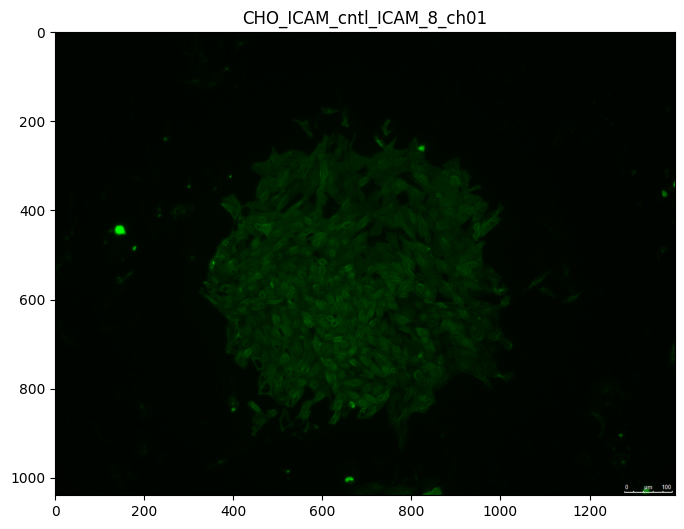

In [79]:
path = lista_arquivos_cont_icam_fluo[12] #chamando a primeira imagem
img = Image.open(path) #abrinado a primeira imagem

plt.figure(figsize=(8,8)) #tamanho da imagem
plt.imshow(img) #abrindo a imagem
plt.title(path[50:-4]) #título recortando o nome do título que corresponde o caminho da imagem[50:-4]
plt.show()

In [80]:
img_df = img_to_df(img=img) #chamando a função criada e como parâmetro está sendo passado a imagem organizada na pasta lá em cima.
img_df.head()

,red,green,blue
0,0.0,0.015686,0.0
1,0.0,0.015686,0.0
2,0.0,0.015686,0.0
3,0.0,0.015686,0.0
4,0.0,0.015686,0.0


In [81]:
img_df_green = img_df['green'].copy() #copiando apenas a coluna verde da df original
freq = (
    img_df_green.value_counts(normalize=True)
    .to_frame()
    .reset_index()
    .rename(columns={'index':'green', 'green':'proportion'})
    .sort_values('green', ascending=False)
)
freq.head()

,green,proportion
63,1.000000,0.000244
141,0.996078,0.000006
139,0.992157,0.000006
128,0.988235,0.000006
110,0.984314,0.000010


In [82]:
soma = 0 #igualando a variavel a 0
for n in range(len(freq)): #iteração para percorrer na df e somar os valores da coluna 1
  soma += freq.iloc[n,1]
  if soma >= 0.001: #5% dos dados
    print(soma)
    break
print(freq.iloc[n,:])

0.0010181808134394348
green         0.368627
proportion    0.000021
Name: 88, dtype: float64


In [83]:
img_df_vir_crtl = img_df.copy()

In [84]:
novo_valor = 0.0  # converter os valores em zero

display(freq.iloc[n, 0])
img_df_vir_crtl.loc[img_df_vir_crtl['green'] >= freq.iloc[n, 0], 'green'] = novo_valor
img_df_vir_crtl.head()

0.3686274509803922

,red,green,blue
0,0.0,0.015686,0.0
1,0.0,0.015686,0.0
2,0.0,0.015686,0.0
3,0.0,0.015686,0.0
4,0.0,0.015686,0.0


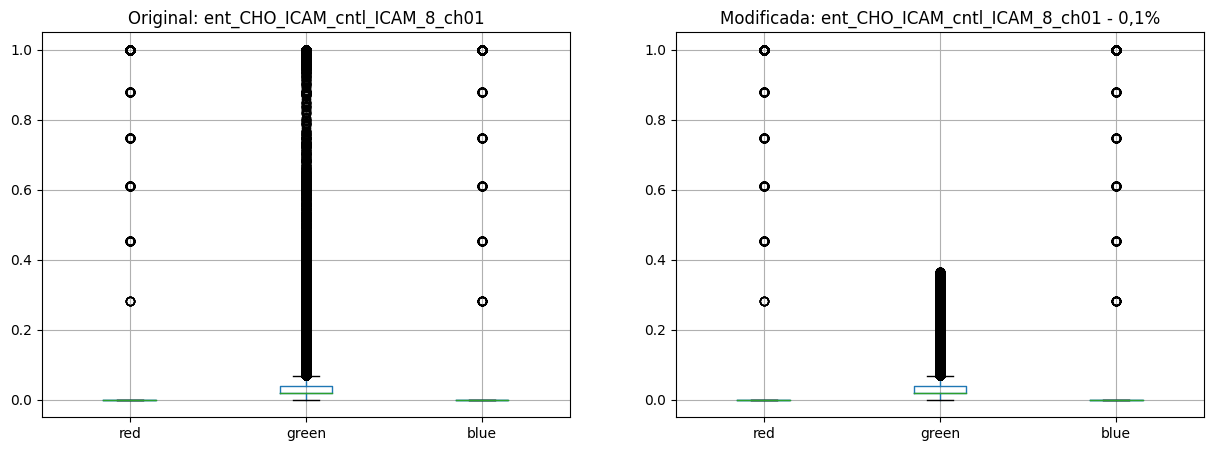

In [85]:
plt.figure(figsize=(15,5))

plt.subplot(1, 2, 1)
plt.title(f"Original: {path[46:-4]}")
img_df.boxplot()

plt.subplot(1, 2, 2)
plt.title(f"Modificada: {path[46:-4]} - 0,1%")
img_df_vir_crtl.boxplot()
plt.show()

Regression Analysis:
Slope = 0.9867 (Ideally close to 1.0)
Intercept = 0.0013 (Ideally close to 0.0)
Pearson R = 0.8995


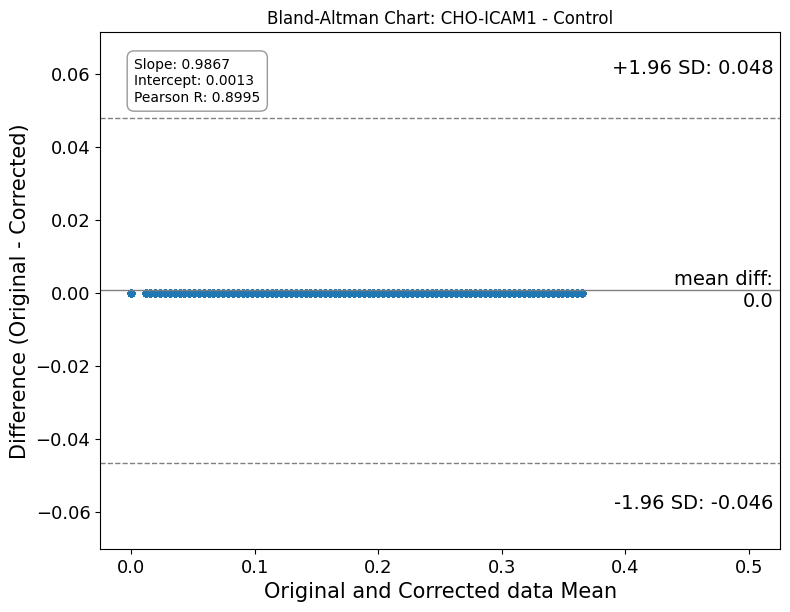

In [86]:
title='CHO-ICAM1 - Control'
bland_altman_grafic(valores_observados=img_df['green'], valores_preditos=img_df_vir_crtl['green'], title=title)

--- Sensitivity Analysis Table (CHO-ICAM1 - Control) ---
Threshold (%) Resulting MFI
        0.01%        0.0460
        0.05%        0.0460
        0.10%        0.0460
        0.20%        0.0460
        0.50%        0.0460
        1.00%        0.0460




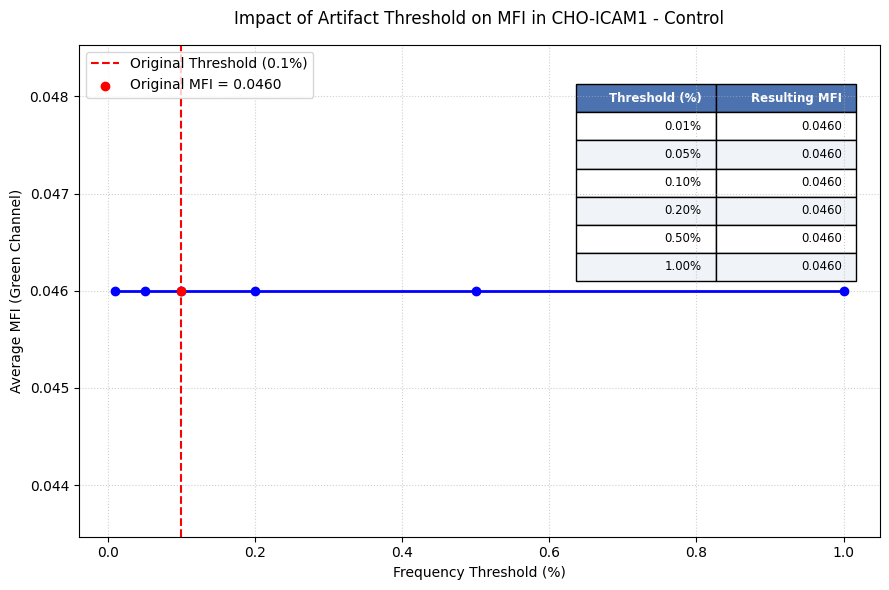

In [87]:
analise_indice_corte(df_test=img_df, title=title)

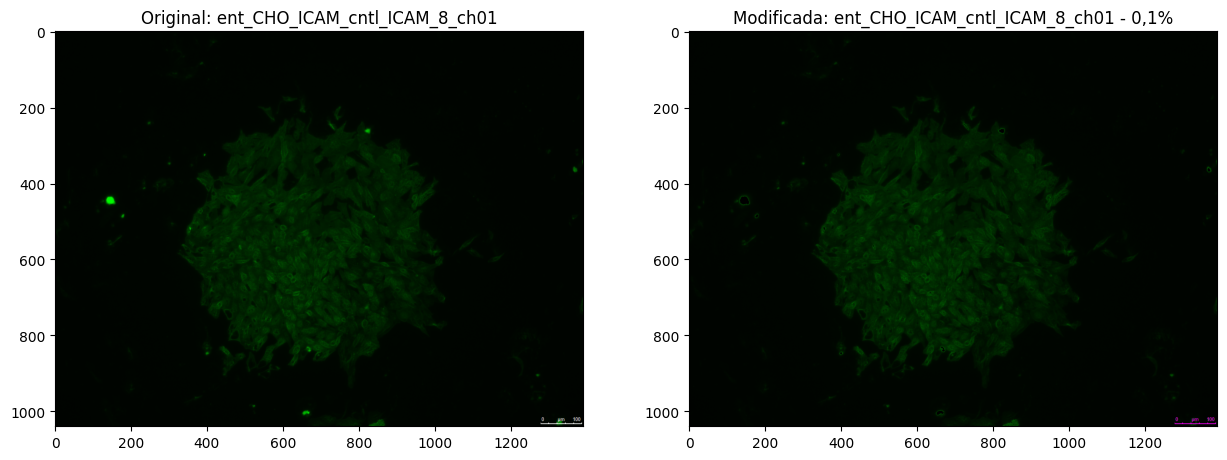

In [88]:
plt.figure(figsize=(15,15))

plt.subplot(1, 2, 1)
plt.imshow(np.array(img_df).reshape(1040, 1392, 3))
plt.title(f"Original: {path[46:-4]}")

plt.subplot(1, 2, 2)
plt.imshow(np.array(img_df_vir_crtl).reshape(1040, 1392, 3))
plt.title(f"Modificada: {path[46:-4]} - 0,1%")

plt.show()

In [89]:
img_df_grupo = pd.DataFrame() #criando uma df
img_dict = {} #criando um dicionário

for path in lista_arquivos_cont_icam_fluo:  #laço para pasta o que tiver em lista de arquivos controle
  path_key = path.split("Experiment_")[1][:-4]
  img = Image.open(path)              #abrinado a imagem que contem em path
  img_df_modif = img_df_vir_crtl
  img_df_grupo[path_key] = img_df_modif['green'] #renomeando a coluna com o final do nome do ar arquivo e sustituindo a coluna green

  img_dict[path_key] = img_df_modif


img_df_grupo.head()

,CHO_ICAM_cntl_cel_1_ch01,CHO_ICAM_cntl_cel_2_ch01,CHO_ICAM_cntl_cel_3_ch01,CHO_ICAM_cntl_cel_4_ch01,CHO_ICAM_cntl_ICAM_10_ch01,CHO_ICAM_cntl_ICAM_1_ch01,CHO_ICAM_cntl_ICAM_2_ch01,CHO_ICAM_cntl_ICAM_3_ch01,CHO_ICAM_cntl_ICAM_4_ch01,CHO_ICAM_cntl_ICAM_5_ch01,...,CHO_ICAM_cntl_sec_Mouse_2_ch01,CHO_ICAM_cntl_sec_Mouse_3_ch01,CHO_ICAM_cntl_sec_Mouse_4_ch01,CHO_ICAM_cntl_sec_Rabbit_1_ch01,CHO_ICAM_cntl_sec_Rabbit_2_ch01,CHO_ICAM_cntl_sec_Rabbit_3_ch01,CHO_ICAM_cntl_sec_Rabbit_4_ch01,CHO_ICAM_cntl_sec_Rabbit_6_ch01,CHO_ICAM_cntl_sec_Rabbit_7_ch01,CHO_ICAM_cntl_sec_Rabbit_8_ch01
0,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,...,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686
1,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,...,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686
2,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,...,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686
3,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,...,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686
4,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,...,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686,0.015686


In [90]:
img_df_grupo.describe()

,CHO_ICAM_cntl_cel_1_ch01,CHO_ICAM_cntl_cel_2_ch01,CHO_ICAM_cntl_cel_3_ch01,CHO_ICAM_cntl_cel_4_ch01,CHO_ICAM_cntl_ICAM_10_ch01,CHO_ICAM_cntl_ICAM_1_ch01,CHO_ICAM_cntl_ICAM_2_ch01,CHO_ICAM_cntl_ICAM_3_ch01,CHO_ICAM_cntl_ICAM_4_ch01,CHO_ICAM_cntl_ICAM_5_ch01,...,CHO_ICAM_cntl_sec_Mouse_2_ch01,CHO_ICAM_cntl_sec_Mouse_3_ch01,CHO_ICAM_cntl_sec_Mouse_4_ch01,CHO_ICAM_cntl_sec_Rabbit_1_ch01,CHO_ICAM_cntl_sec_Rabbit_2_ch01,CHO_ICAM_cntl_sec_Rabbit_3_ch01,CHO_ICAM_cntl_sec_Rabbit_4_ch01,CHO_ICAM_cntl_sec_Rabbit_6_ch01,CHO_ICAM_cntl_sec_Rabbit_7_ch01,CHO_ICAM_cntl_sec_Rabbit_8_ch01
count,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,...,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06,1.447680e+06
mean,4.601302e-02,4.601302e-02,4.601302e-02,4.601302e-02,4.601302e-02,4.601302e-02,4.601302e-02,4.601302e-02,4.601302e-02,4.601302e-02,...,4.601302e-02,4.601302e-02,4.601302e-02,4.601302e-02,4.601302e-02,4.601302e-02,4.601302e-02,4.601302e-02,4.601302e-02,4.601302e-02
std,5.019052e-02,5.019052e-02,5.019052e-02,5.019052e-02,5.019052e-02,5.019052e-02,5.019052e-02,5.019052e-02,5.019052e-02,5.019052e-02,...,5.019052e-02,5.019052e-02,5.019052e-02,5.019052e-02,5.019052e-02,5.019052e-02,5.019052e-02,5.019052e-02,5.019052e-02,5.019052e-02
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02,...,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02
50%,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02,...,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02,1.960784e-02
75%,3.921569e-02,3.921569e-02,3.921569e-02,3.921569e-02,3.921569e-02,3.921569e-02,3.921569e-02,3.921569e-02,3.921569e-02,3.921569e-02,...,3.921569e-02,3.921569e-02,3.921569e-02,3.921569e-02,3.921569e-02,3.921569e-02,3.921569e-02,3.921569e-02,3.921569e-02,3.921569e-02
max,3.647059e-01,3.647059e-01,3.647059e-01,3.647059e-01,3.647059e-01,3.647059e-01,3.647059e-01,3.647059e-01,3.647059e-01,3.647059e-01,...,3.647059e-01,3.647059e-01,3.647059e-01,3.647059e-01,3.647059e-01,3.647059e-01,3.647059e-01,3.647059e-01,3.647059e-01,3.647059e-01


In [91]:
if save:
    joblib.dump(pd.DataFrame(img_df_grupo_vir), f'{link}save/dataframe-CHOICAM-Ctrl-fluorescente-0,01%-{data}.gz')

# Calculando a comparação entre as imagens

In [92]:
img_df_grupo.sum().mean()

66612.12549019608

In [93]:
img_df_grupo.sum().median()

66612.12549019608

In [94]:
# 745 - GTS
display(len(lista_arquivos_fluo))

# 745 - VIR
display(len(lista_arquivos_fluo_vir))

# 745 - Ctrl
display(len(lista_arquivos_fluo_vir_ctrl))

# ICAM - GTS
display(len(lista_arquivos_gst_icam_fluo))

# ICAM - VIR
display(len(lista_arquivos_cont_icam_fluo))

# ICAM - Ctrl
display(len(lista_arquivos_vir_icam_fluo))

21

31

26

40

25

43

In [95]:
# 1. Função para calcular a Intensidade Média de Fluorescência (MFI) da imagem
def calcular_mfi(path):
    img = Image.open(path)
    img_array = np.array(img)
    # Subtração de background pode ser inserida aqui caso você tenha as imagens de controle
    return np.mean(img_array)


# 2. Extração dos valores numéricos de MFI para cada imagem
mfi_gst = [calcular_mfi(p) for p in lista_arquivos_fluo] # usando sua lista_arquivos_fluo (GTS)
mfi_vir = [calcular_mfi(p) for p in lista_arquivos_fluo_vir]

# 3. Reporte de Médias de Grupo (Group Means)
mean_gst, std_gst = np.mean(mfi_gst), np.std(mfi_gst)
mean_vir, std_vir = np.mean(mfi_vir), np.std(mfi_vir)
print(f"MFI GST: Média = {mean_gst:.2f}, Desvio Padrão = {std_gst:.2f}")
print(f"MFI VIR: Média = {mean_vir:.2f}, Desvio Padrão = {std_vir:.2f}")

# 4. Teste Estatístico (Test Statistics) - Teste T de Welch (assume variâncias diferentes)
t_stat, p_val = stats.ttest_ind(mfi_vir, mfi_gst, equal_var=False)
print(f"Teste T Independente: t = {t_stat:.4f}, Valor-p = {p_val:.4e}")

# 5. Tamanho do Efeito (Effect Size) - Cohen's d
n1, n2 = len(mfi_vir), len(mfi_gst)
s_pooled = np.sqrt(((n1 - 1) * std_vir**2 + (n2 - 1) * std_gst**2) / (n1 + n2 - 2))
cohens_d = (mean_vir - mean_gst) / s_pooled
print(f"Tamanho do Efeito (Cohen's d): {cohens_d:.4f}")

MFI GST: Média = 4.30, Desvio Padrão = 0.62
MFI VIR: Média = 5.86, Desvio Padrão = 2.56
Teste T Independente: t = 3.1940, Valor-p = 2.9625e-03
Tamanho do Efeito (Cohen's d): 0.7702


In [96]:
# 1. Função para calcular a Intensidade Média de Fluorescência (MFI) da imagem
def calcular_mfi(path):
    img = Image.open(path)
    img_array = np.array(img)
    # Subtração de background pode ser inserida aqui caso você tenha as imagens de controle
    return np.mean(img_array)


# 2. Extração dos valores numéricos de MFI para cada imagem
mfi_gst = [calcular_mfi(p) for p in lista_arquivos_gst_icam_fluo] # usando sua lista_arquivos_fluo (GTS)
mfi_vir = [calcular_mfi(p) for p in lista_arquivos_cont_icam_fluo]

# 3. Reporte de Médias de Grupo (Group Means)
mean_gst, std_gst = np.mean(mfi_gst), np.std(mfi_gst)
mean_vir, std_vir = np.mean(mfi_vir), np.std(mfi_vir)
print(f"MFI GST: Média = {mean_gst:.2f}, Desvio Padrão = {std_gst:.2f}")
print(f"MFI VIR: Média = {mean_vir:.2f}, Desvio Padrão = {std_vir:.2f}")

# 4. Teste Estatístico (Test Statistics) - Teste T de Welch (assume variâncias diferentes)
t_stat, p_val = stats.ttest_ind(mfi_vir, mfi_gst, equal_var=False)
print(f"Teste T Independente: t = {t_stat:.4f}, Valor-p = {p_val:.4e}")

# 5. Tamanho do Efeito (Effect Size) - Cohen's d
n1, n2 = len(mfi_vir), len(mfi_gst)
s_pooled = np.sqrt(((n1 - 1) * std_vir**2 + (n2 - 1) * std_gst**2) / (n1 + n2 - 2))
cohens_d = (mean_vir - mean_gst) / s_pooled
print(f"Tamanho do Efeito (Cohen's d): {cohens_d:.4f}")

MFI GST: Média = 2.30, Desvio Padrão = 0.67
MFI VIR: Média = 1.80, Desvio Padrão = 1.29
Teste T Independente: t = -1.7451, Valor-p = 9.0524e-02
Tamanho do Efeito (Cohen's d): -0.5193
